## Support Functions

In [5]:
from matplotlib import gridspec
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import os
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import seaborn as sns


def unique(sequence):
    seen = set()
    return [x for x in sequence if not (x in seen or seen.add(x))]


def compute_q_correlation(df, *, method="spearman"):
    """
    Compute correlation matrix.

    method: "pearson", "spearman", or "kendall"
    """

    corr = df.corr(method=method)
    return corr


def plot_q_correlation_heatmap(df, *, title, method="spearman", user_hardness=None, vmin=-1, vmax=1):
    # Only include keys that actually exist in the current dataframe columns
    desired_order = [v for v in PAPER_MODEL_NAMES.values() if v in df.columns]

    if user_hardness is None:
        category_iter = [(None, None)]
    else:
        category_iter = [
            (cat, user_hardness[user_hardness["difficulty_group"] == cat])
            for cat in user_hardness["difficulty_group"].cat.categories
        ]

    for category_name, hardness_df in category_iter:
        subdf = df.copy()
        if hardness_df is not None:
            subdf = subdf[subdf.index.isin(hardness_df.index)]

        subdf = subdf[desired_order]
        corr = compute_q_correlation(subdf, method=method)

        triag_mask = np.triu(corr)
        plt.figure(figsize=(8, 6))
        ax = sns.heatmap(
            corr,
            annot=True,
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            square=True,
            fmt='.2f',
            mask=triag_mask
        )
        ax.tick_params(axis='x', labelrotation=45)
        plt.xlabel("")
        plt.ylabel("")
        final_title = title
        if category_name is not None:
            final_title += f" ({category_name})"
        plt.title(final_title, fontsize=14)
        plt.tight_layout()
        plt.show()


def plot_multiple_q_correlation_heatmaps(data_pairs, title, *, method="spearman", vmin=-1, vmax=1):
    """
    Plots multiple correlation heatmaps side-by-side.
    - Uses the first dataset to define the "Master Order" of algorithms.
    - If subsequent datasets miss an algorithm, empty space is preserved.
    - Y-axis labels only on the first plot.
    - Shared colorbar on the far right.
    """
    n_plots = len(data_pairs)
    if n_plots == 0:
        return

    # 1. Define Master Order based on the FIRST dataset (Default)
    # We filter PAPER_MODEL_NAMES to find which values exist in the first df
    first_df = data_pairs[0][1]
    master_keys = [v for v in PAPER_MODEL_NAMES.values() if v in first_df.columns]

    # 2. Setup Figure Layout
    # n_plots columns + 1 narrow column for the colorbar
    fig = plt.figure(figsize=(5.5 * n_plots + 1, 6))
    gs = gridspec.GridSpec(1, n_plots + 1, width_ratios=[1] * n_plots + [0.05], wspace=0.05)

    # Create axes
    axes = [fig.add_subplot(gs[0, i]) for i in range(n_plots)]
    cax = fig.add_subplot(gs[0, n_plots])

    for i, (title, df) in enumerate(data_pairs):
        ax = axes[i]

        # 3. Reindex to enforce the Master Order
        # This inserts NaN columns for any model present in 'master_keys' but missing in 'df'
        subdf = df.reindex(columns=master_keys)

        # 4. Compute Correlation
        # Correlations with NaN columns result in NaN rows/cols, which Heatmap leaves empty (white)
        corr = compute_q_correlation(subdf, method=method)
        mask = np.triu(np.ones_like(corr, dtype=bool))

        # 5. Plot
        # We generate the colorbar only on the LAST plot (i == n_plots - 1)
        # but we draw it in the dedicated axis 'cax'
        is_last_plot = (i == n_plots - 1)

        sns.heatmap(
            corr,
            ax=ax,
            annot=True,
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            square=True,
            fmt='.2f',
            mask=mask,
            cbar=is_last_plot,
            cbar_ax=cax if is_last_plot else None
        )
        # 6. Formatting

        ax.set_title(title, fontsize=12, pad=10)
        ax.set_xlabel("")
        ax.set_ylabel("")

        # X-Axis: Always show and rotate
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

        # Y-Axis: Show ONLY on the first plot
        if i == 0:
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
        else:
            ax.set_yticks([])
            ax.set_yticklabels([])

        if is_last_plot:
            cax.set_title("")
            cax.set_ylabel("")
            cax.set_xlabel("")

    fig.tight_layout(w_pad=0.3, h_pad=0.3)

    # --- Save figure ---
    fig.savefig(
        os.path.join(".", "q1_model_comparison.pdf"),
        dpi=1300,
        bbox_inches="tight",
        pad_inches=0.05
    )
    fig.show()


PAPER_MODEL_NAMES = {
    "fastai": "PMF",
    "clickpop": "Popularity",
    "lightgcn": "LightGCN",
    "ease": "EASE",
    "als": "ALS",
    "sar-cosine": "SAR-Cosine",
    "sar-jaccard": "SAR-Jaccard",
    "bpr": "BPR",
    "random": "Random",
    "lightfm": "LightFM",
    "lightfmf": "LightFM-F",
    "sasrec": "SASRec"
}

In [6]:
df_by_bias_type = {}
METRIC_NAME = "ndcg@100"

In [7]:
# =========================
# Configuration
# =========================

CUTOFFS = [100, 50, 10, 5]

METRIC_FAMILIES = {
    "nDCG@K": [f"ndcg@{k}" for k in CUTOFFS],
    "nDCG@K (Unbiased)": [f"unbiased_ndcg@{k}" for k in CUTOFFS],
    "Precision@K": [f"precision@{k}" for k in CUTOFFS],
    "Precision@K (Unbiased)": [f"unbiased_precision@{k}" for k in CUTOFFS],
    "Recall@K": [f"recall@{k}" for k in CUTOFFS],
    "Recall@K (Unbiased)": [f"unbiased_recall@{k}" for k in CUTOFFS],
    "MRR@K": [f"mean_mrr@{k}" for k in CUTOFFS],
    # "MRR": ["mean_mrr"],
    "AUC": ["group_auc"],
}

SAMPLE_SIZES = [1000, 500, 200, 100, 50, 20, 10, 5, 2, 1]

SAMPLER_FAMILIES = {
    "Full": ["CNCFULL"],
    "Exposed": ["EXPOSED"],
    "Random@e": ["CNCRANDEXPO"],
    "Random@n": [f"CNCRANDOM@{n}" for n in SAMPLE_SIZES],
    "Popularity@n": [f"POPULARITY@{n}" for n in SAMPLE_SIZES],
    "Positivity@n": [f"POSITIVITY@{n}" for n in SAMPLE_SIZES],
    "Skew@n": [f"SKEW@{n}" for n in SAMPLE_SIZES],
    "WTD@n": [f"WTD@{n}" for n in SAMPLE_SIZES],
    "WTDH@n": [f"WTDH@{n}" for n in SAMPLE_SIZES],
}

# =========================
# Statistical Winners & Losers
# =========================

def compute_metric_winners_wide(df, model_col, metric_names, alpha=0.05):
    """Identify best models (Higher Score = Better)"""
    winners = {}
    for metric in metric_names:
        if metric not in df.columns: continue
        pivot = df.pivot_table(index=df.index, columns=model_col, values=metric)
        if pivot.empty: continue

        means = pivot.mean()
        leader = means.idxmax() # Assumption: Higher is better

        pvals, tested_models = [], []
        for model in pivot.columns:
            if model == leader: continue

            # Test: Is Leader > Model?
            x, y = pivot[leader], pivot[model]
            mask = x.notna() & y.notna()
            if mask.sum() < 5: pvals.append(1.0)
            else:
                try:
                    _, p = wilcoxon(x[mask], y[mask], alternative="greater")
                    pvals.append(p)
                except ValueError: pvals.append(1.0)
            tested_models.append(model)

        if pvals:
            corrected = multipletests(pvals, alpha=alpha, method="holm")[1]
        else:
            corrected = []

        # If p >= alpha, we fail to reject that Leader > Model -> They are tied
        winners_metric = [leader]
        for model, p_corr in zip(tested_models, corrected):
            if p_corr >= alpha:
                winners_metric.append(model)
        winners[metric] = sorted(set(winners_metric))
    return winners

def compute_metric_losers_wide(df, model_col, metric_names, alpha=0.05):
    """Identify worst models (Statistically tied with the lowest score)"""
    losers = {}
    for metric in metric_names:
        if metric not in df.columns: continue
        pivot = df.pivot_table(index=df.index, columns=model_col, values=metric)
        if pivot.empty: continue

        means = pivot.mean()
        loser = means.idxmin() # Worst model (lowest score)

        pvals, tested_models = [], []
        for model in pivot.columns:
            if model == loser: continue

            # Test: Is Model > Loser? (Is the other model significantly better?)
            x, y = pivot[model], pivot[loser]
            mask = x.notna() & y.notna()

            if mask.sum() < 5: pvals.append(1.0)
            else:
                try:
                    # We check if 'model' is significantly GREATER than 'loser'
                    _, p = wilcoxon(x[mask], y[mask], alternative="greater")
                    pvals.append(p)
                except ValueError: pvals.append(1.0)
            tested_models.append(model)

        if pvals:
            corrected = multipletests(pvals, alpha=alpha, method="holm")[1]
        else:
            corrected = []

        # If p < alpha: Model is significantly better.
        # If p >= alpha: Model is NOT significantly better -> Tied with Loser.
        losers_metric = [loser]
        for model, p_corr in zip(tested_models, corrected):
            if p_corr >= alpha:
                losers_metric.append(model)
        losers[metric] = sorted(set(losers_metric))
    return losers

# =========================
# Ranking Utilities
# =========================

def bootstrap_ranks_wide(df, model_col, metric_names, n_bootstrap=1000, alpha=0.05):
    rng = np.random.default_rng(42)

    # Pre-pivot for speed
    pivoted_metrics = {}
    valid_metrics = []
    for met in metric_names:
        if met in df.columns:
            pivoted_metrics[met] = df.pivot_table(index=df.index, columns=model_col, values=met)
            valid_metrics.append(met)

    models = df[model_col].unique()
    store = {(m, met): [] for m in models for met in valid_metrics}

    if not valid_metrics: return pd.DataFrame()
    n_samples = len(pivoted_metrics[valid_metrics[0]])

    for _ in range(n_bootstrap):
        # Paired Sampling of User Indices
        boot_indices = rng.integers(0, n_samples, size=n_samples)

        for met in valid_metrics:
            wide_df = pivoted_metrics[met]
            # Fast numpy indexing
            means = np.nanmean(wide_df.values[boot_indices, :], axis=0)

            # Rank Means (Higher Score = Better Rank)
            ranks = pd.Series(means, index=wide_df.columns).rank(ascending=False, method="average")
            for model, r in ranks.items():
                store[(model, met)].append(r)

    rows = []
    for (model, metric), vals in store.items():
        vals = np.asarray(vals)
        rows.append({
            "model": model,
            "metric": metric,
            "mean_rank": vals.mean(),
            "ci_low": np.percentile(vals, 100 * alpha / 2),
            "ci_high": np.percentile(vals, 100 * (1 - alpha / 2)),
        })
    return pd.DataFrame(rows)


# =========================
# Visualization
# =========================
def plot_heatmaps_by_cutoff(rank_ci_df, winners_by_metric):

    cutoffs = CUTOFFS

    # Global model ordering
    model_order = (
        rank_ci_df.groupby("model")["mean_rank"]
        .mean()
        .sort_values()
        .index
    )

    # Grid with external colorbar
    fig = plt.figure(figsize=(4.8 * len(cutoffs) + 0.8, 6))
    gs = gridspec.GridSpec(1, len(cutoffs) + 1, width_ratios=[1]*len(cutoffs) + [0.05])

    axes = [fig.add_subplot(gs[i]) for i in range(len(cutoffs))]
    cax = fig.add_subplot(gs[-1])

    for ax, k in zip(axes, cutoffs):

        metrics_k = []
        labels_k = []

        for family, metrics in METRIC_FAMILIES.items():
            for m in metrics:
                if m.endswith(f"@{k}") or m in ["group_auc", "mean_mrr"]:
                    metrics_k.append(m)
                    if "@K" in family:
                        labels_k.append(family.replace("@K", f"@{k}"))
                    else:
                        labels_k.append(family)

        df_k = rank_ci_df[rank_ci_df["metric"].isin(metrics_k)]

        pivot = (
            df_k.pivot(index="model", columns="metric", values="mean_rank")
            .loc[model_order, metrics_k]
        )

        annot = pivot.copy().astype(str)
        for m in pivot.index:
            for met in pivot.columns:
                val = f"{pivot.loc[m, met]:.2f}"
                if m in winners_by_metric.get(met, []):
                    annot.loc[m, met] = rf"$\mathbf{{{val}}}$"
                else:
                    annot.loc[m, met] = val

        sns.heatmap(
            pivot,
            ax=ax,
            cmap="viridis_r",
            annot=annot,
            fmt="",
            linewidths=0.4,
            cbar=(ax == axes[-1]),
            cbar_ax=cax if ax == axes[-1] else None,
        )

        ax.set_title(f"k = {k}")
        ax.set_xlabel("")
        ax.set_xticklabels(labels_k, rotation=45, ha="right")

        if ax is axes[0]:
            ax.set_ylabel("Model")
            ax.set_yticklabels(
                [PAPER_MODEL_NAMES.get(m, m) for m in model_order],
                rotation=0
            )
        else:
            ax.set_ylabel("")
            ax.set_yticks([])
            ax.set_yticklabels([])

    cax.set_ylabel("Average Rank (lower is better)")

    fig.suptitle(
        "Model Ranking per Metric and Cutoff\n"
        "Bold indicates statistically non-inferior models "
        "(paired Wilcoxon, Holm-corrected, α = 0.05)",
        y=1.05
    )

    plt.tight_layout()
    plt.show()


# =========================
# End-to-end
# =========================

def generate_final_ranking_figure(
    df,
    model_col="model",
    alpha=0.05,
    n_bootstrap=1000,
):
    metric_names = df.columns.difference([model_col]).tolist()

    winners = compute_metric_winners_wide(df, model_col, metric_names, alpha)
    rank_ci_df = bootstrap_ranks_wide(
        df, model_col, metric_names, n_bootstrap=n_bootstrap, alpha=alpha
    )

    plot_heatmaps_by_cutoff(rank_ci_df, winners)


In [8]:
# =========================
# Visualization
# =========================
def plot_ranking_lines(rank_ci_df, winners_by_metric, losers_by_metric):

    # 1. Setup Metrics Axis (Standard setup)
    ordered_metrics = []
    xtick_labels = []
    family_boundaries = []
    current_idx = 0

    for family, metrics in METRIC_FAMILIES.items():
        valid = [m for m in metrics if m in rank_ci_df['metric'].unique()]
        if valid:
            ordered_metrics.extend(valid)
            for m in valid:
                xtick_labels.append(m.split("@")[-1] if "@" in m else "")
            family_boundaries.append((current_idx, current_idx + len(valid), family))
            current_idx += len(valid)

    if not ordered_metrics: return

    # 2. Prepare Data
    plot_df = rank_ci_df[rank_ci_df['metric'].isin(ordered_metrics)].copy()
    metric_to_x = {m: i for i, m in enumerate(ordered_metrics)}
    plot_df['x'] = plot_df['metric'].map(metric_to_x)

    # Sort models by overall rank for consistent colors
    model_order = plot_df.groupby('model')['mean_rank'].mean().sort_values().index.tolist()
    colors = sns.color_palette("tab10", n_colors=len(model_order))
    model_colors = {m: c for m, c in zip(model_order, colors)}

    # Initialize Plot - Add extra left padding for the labels
    fig, ax = plt.subplots(figsize=(len(ordered_metrics) * 0.8 + 3, 8))

    # Background shading
    for i, (start, end, family) in enumerate(family_boundaries):
        if i % 2 == 1:
            ax.axvspan(start - 0.5, end - 0.5, color='gray', alpha=0.05, lw=0)
        mid = (start + end - 1) / 2
        ax.text(mid, ax.get_ylim()[1] if ax.get_ylim() else 0.5, family,
                ha='center', va='bottom', fontsize=10, fontweight='bold', transform=ax.get_xaxis_transform())

    # 3. Plot Lines & Markers
    for model in model_order:
        m_df = plot_df[plot_df['model'] == model].sort_values('x')

        # Line
        ax.plot(m_df['x'], m_df['mean_rank'], marker='', linestyle='-', linewidth=2,
                alpha=0.75, color=model_colors[model])

        # Markers
        for _, row in m_df.iterrows():
            met = row['metric']
            is_winner = model in winners_by_metric.get(met, [])
            is_loser = model in losers_by_metric.get(met, [])

            if is_winner:
                marker, size, zorder = '*', 180, 10
                face, edge = model_colors[model], 'black'
            elif is_loser:
                marker, size, zorder = 'v', 100, 10
                face, edge = model_colors[model], 'black'
            else:
                marker, size, zorder = 'o', 40, 5
                face, edge = model_colors[model], 'white'

            ax.scatter(
                row['x'], row['mean_rank'], marker=marker, s=size,
                color=face, edgecolors=edge, zorder=zorder
            )

    # 4. Smart Y-Axis Labeling (Collision Avoidance)
    ax.invert_yaxis()
    ax.set_yticks([]) # Turn off standard ticks
    ax.set_ylabel("")

    # Get start data (x=0) and sort by rank
    start_data = plot_df[plot_df['x'] == 0].sort_values('mean_rank')

    # Create a list of label objects
    labels_data = []
    for _, row in start_data.iterrows():
        labels_data.append({
            'rank': row['mean_rank'],
            'name': PAPER_MODEL_NAMES.get(row['model'], row['model']),
            'color': model_colors[row['model']]
        })

    # --- CLUSTERING ALGORITHM ---
    # Group items that are closer than `threshold` units apart
    threshold = 0.5  # Adjust this if labels are still touching
    clusters = []
    if labels_data:
        current_cluster = [labels_data[0]]
        for i in range(1, len(labels_data)):
            prev = current_cluster[-1]
            curr = labels_data[i]

            # If strictly tied or very close
            if (curr['rank'] - prev['rank']) < threshold:
                current_cluster.append(curr)
            else:
                clusters.append(current_cluster)
                current_cluster = [curr]
        clusters.append(current_cluster)

    # --- RENDERING ---
    # Draw each cluster fanned out vertically
    for cluster in clusters:
        avg_rank = sum(d['rank'] for d in cluster) / len(cluster)
        n = len(cluster)

        # Vertical spacing step (how far apart to push stacked labels)
        step = 0.6

        # Calculate top-most Y position for this cluster
        # We center the stack around the 'avg_rank'
        start_y = avg_rank - ((n - 1) * step / 2)

        for i, item in enumerate(cluster):
            y_pos = start_y + (i * step)

            # Draw Text
            # x=-0.02 (in axes coordinates) puts it just to the left of the plot
            ax.text(
                -0.02, y_pos,
                item['name'],
                color=item['color'],
                fontsize=11,
                fontweight='bold',
                ha='right',
                va='center',
                transform=ax.get_yaxis_transform() # Allows x in axes coords, y in data coords
            )

    # 5. Final Formatting
    ax.set_xticks(range(len(ordered_metrics)))
    ax.set_xticklabels(xtick_labels)

    legend_elements = [
        Line2D([0], [0], marker='*', color='w', markerfacecolor='gray', markersize=15, label='Statistically Best'),
        Line2D([0], [0], marker='v', color='w', markerfacecolor='gray', markersize=10, label='Statistically Worst'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='In-between'),
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), title="Significance")

    ax.set_title(
        "Model Ranking Stability",
        pad=20
    )

    plt.tight_layout()
    plt.show()

# =========================
# Main Wrapper
# =========================
def generate_final_ranking_figure2(df, model_col="model", alpha=0.05, n_bootstrap=1000):
    metric_names = df.columns.difference([model_col]).tolist()

    # 1. Compute Stats
    winners = compute_metric_winners_wide(df, model_col, metric_names, alpha)
    losers = compute_metric_losers_wide(df, model_col, metric_names, alpha)

    # 2. Bootstrap Ranks
    rank_ci_df = bootstrap_ranks_wide(df, model_col, metric_names, n_bootstrap, alpha)

    # 3. Plot
    plot_ranking_lines(rank_ci_df, winners, losers)

In [9]:
# =========================
# 2. Visualization (Stacked)
# =========================

def plot_stacked_ranking_lines(results_list, global_model_colors, metric_families=METRIC_FAMILIES):
    """
    Plots stacked ranking charts.
    results_list: List of tuples (Title, rank_ci_df, winners, losers)
    global_model_colors: Dictionary mapping model names to colors
    """
    n_plots = len(results_list)
    if n_plots == 0: return

    # Determine Metrics Order (Union of all metrics found)
    # To keep x-axis consistent, we try to use the first dataset's metrics,
    # or a union if they differ significantly. Here we stick to the config order.
    sample_df = results_list[0][1] # rank_ci_df of first dataset
    ordered_metrics = []
    xtick_labels = []
    family_boundaries = []
    current_idx = 0

    # Build X-Axis based on Configuration and what exists in data
    # (We assume all datasets share the same metrics structure for alignment)
    for family, metrics in metric_families.items():
        # Check if metric exists in ANY dataset
        all_metrics_in_data = set().union(*[r[1]['metric'].unique() for r in results_list])
        valid = [m for m in metrics if m in all_metrics_in_data]

        if valid:
            ordered_metrics.extend(valid)
            for m in valid:
                xtick_labels.append(m.split("@")[-1] if "@" in m else "")
            family_boundaries.append((current_idx, current_idx + len(valid), family))
            current_idx += len(valid)

    if not ordered_metrics: return

    # Initialize Figure (Height scales with number of plots)
    # Width calculation: metric count + padding for Y-labels
    fig, axes = plt.subplots(
        nrows=n_plots,
        ncols=1,
        figsize=(len(ordered_metrics) * 0.8 + 3, 5 * n_plots),
        sharex=True
    )

    if n_plots == 1: axes = [axes] # Handle single plot case

    # Iterate over datasets and axes
    for ax_idx, (ax, (title, rank_ci_df, winners, losers)) in enumerate(zip(axes, results_list)):

        # Filter Data
        plot_df = rank_ci_df[rank_ci_df['metric'].isin(ordered_metrics)].copy()
        metric_to_x = {m: i for i, m in enumerate(ordered_metrics)}
        plot_df['x'] = plot_df['metric'].map(metric_to_x)

        # Background shading (Families)
        for i, (start, end, family) in enumerate(family_boundaries):
            if i % 2 == 1:
                ax.axvspan(start - 0.5, end - 0.5, color='gray', alpha=0.05, lw=0)

            # Label Families ONLY on the top plot
            if ax_idx == 0:
                mid = (start + end - 1) / 2
                ax.text(mid, ax.get_ylim()[1] if ax.get_ylim() else 0.5, family,
                        ha='center', va='bottom', fontsize=14, fontweight='bold',
                        transform=ax.get_xaxis_transform())

        # Plot Lines & Markers
        # Use global colors
        models_in_this_plot = plot_df['model'].unique()

        ax.set_xlim(-0.5, len(ordered_metrics) - 0.5)

        for model in models_in_this_plot:
            if model not in global_model_colors: continue # Should not happen

            m_df = plot_df[plot_df['model'] == model].sort_values('x')
            color = global_model_colors[model]

            # Line
            ax.plot(m_df['x'], m_df['mean_rank'], marker='', linestyle='-', linewidth=3, alpha=0.75, color=color)

            # Markers
            for _, row in m_df.iterrows():
                met = row['metric']
                is_winner = model in winners.get(met, [])
                is_loser = model in losers.get(met, [])

                if is_winner:
                    marker, size, zorder, edge = '*', 180, 10, 'black'
                elif is_loser:
                    marker, size, zorder, edge = 'v', 100, 10, 'black'
                else:
                    marker, size, zorder, edge = 'o', 40, 5, 'white'

                ax.scatter(
                    row['x'], row['mean_rank'], marker=marker, s=size, color=color, edgecolors=edge, zorder=zorder
                )

        # Smart Y-Axis Labeling (Collision Avoidance) - Per Subplot
        ax.invert_yaxis()
        ax.set_yticks([])
        ax.set_ylabel("")

        # Get start data (x=0) for this dataset
        start_data = plot_df[plot_df['x'] == 0].sort_values('mean_rank')

        labels_data = []
        for _, row in start_data.iterrows():
            labels_data.append({
                'rank': row['mean_rank'],
                'name': PAPER_MODEL_NAMES.get(row['model'], row['model']),
                'color': global_model_colors[row['model']]
            })

        # Clustering Logic
        threshold = 0.6
        clusters = []
        if labels_data:
            current_cluster = [labels_data[0]]
            for i in range(1, len(labels_data)):
                prev = current_cluster[-1]
                curr = labels_data[i]
                if (curr['rank'] - prev['rank']) < threshold:
                    current_cluster.append(curr)
                else:
                    clusters.append(current_cluster)
                    current_cluster = [curr]
            clusters.append(current_cluster)

        # Draw Labels
        for cluster in clusters:
            avg_rank = sum(d['rank'] for d in cluster) / len(cluster)
            n = len(cluster)
            step = 0.7 # Spacing between stacked labels
            start_y = avg_rank - ((n - 1) * step / 2)

            for i, item in enumerate(cluster):
                y_pos = start_y + (i * step)
                ax.text(
                    -0.02, y_pos, item['name'], color=item['color'],
                    fontsize=14, fontweight='bold', ha='right', va='center',
                    transform=ax.get_yaxis_transform()
                )

        # Formatting
        ax.set_title(title, loc='left', fontsize=16, fontweight='bold', pad=5, x=-0.01)

        # Only show X-ticks on the bottom-most plot
        if ax_idx == n_plots - 1:
            ax.set_xticks(range(len(ordered_metrics)))
            ax.set_xticklabels(xtick_labels, rotation=0)
            ax.set_xlabel("Cutoff (K)")
        else:
            # Remove x ticks for inner plots to clean up view
            ax.tick_params(labelbottom=False)

    # # Global Legend (Significance)
    # legend_elements = [
    #     Line2D([0], [0], marker='*', color='w', markerfacecolor='gray', markersize=15, label='Statistically Best'),
    #     Line2D([0], [0], marker='v', color='w', markerfacecolor='gray', markersize=10, label='Statistically Worst'),
    #     Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='In-between'),
    # ]
    # # Place legend on the top plot, outside top-right
    # axes[0].legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1.1), title="Significance")

    fig.title = "Model Ranking Stability"
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.1) # Add breathing room between stacked charts
    plt.show()

# =========================
# Main Wrapper
# =========================

def generate_stacked_ranking_figure(dataset_list, model_col="model", alpha=0.05, n_bootstrap=1000, metric_families=METRIC_FAMILIES):
    """
    Main entry point.
    dataset_list: List of tuples [(Title, DataFrame), (Title, DataFrame), ...]
    """

    processed_results = []
    all_models = set()

    print(f"Processing {len(dataset_list)} datasets...")

    # 1. Compute Stats for each dataset
    for title, df in dataset_list:
        metric_names = df.columns.difference([model_col]).tolist()

        print(f"  -> Bootstrapping '{title}'...")
        winners = compute_metric_winners_wide(df, model_col, metric_names, alpha)
        losers = compute_metric_losers_wide(df, model_col, metric_names, alpha)
        rank_ci_df = bootstrap_ranks_wide(df, model_col, metric_names, n_bootstrap, alpha)

        processed_results.append((title, rank_ci_df, winners, losers))

        # Collect all unique models encountered
        all_models.update(df[model_col].unique())

    # 2. Assign Global Colors (Stable across plots)
    # Sort models so assignment is deterministic
    sorted_models = sorted(list(all_models))
    # Use tab20 if many models, else tab10
    palette_name = "tab20" if len(sorted_models) > 10 else "tab10"
    colors = sns.color_palette(palette_name, n_colors=len(sorted_models))
    global_model_colors = dict(zip(sorted_models, colors))

    # 3. Plot Stacked
    plot_stacked_ranking_lines(processed_results, global_model_colors, metric_families)

In [28]:
def plot_stacked_ranking_lines_noalign(results_list, global_model_colors, metric_families=METRIC_FAMILIES, output_file="q2_model_stability.pdf"):
    """
    Plots stacked ranking charts.
    results_list: List of tuples (Title, rank_ci_df, winners, losers)
    global_model_colors: Dictionary mapping model names to colors
    """
    n_plots = len(results_list)
    if n_plots == 0: return

    # Estimate max figure width based on the dataset with the most metrics
    max_metrics = max([len(r[1]['metric'].unique()) for r in results_list])

    # Initialize Figure without sharex
    fig, axes = plt.subplots(
        nrows=n_plots//2,
        ncols=2,
        figsize=((max_metrics * 0.2 + 3) * 2, 3 * n_plots/2),
        sharex=False # Axes are now independent
    )
    axes = axes.flatten()

    if n_plots == 1: axes = [axes] # Handle single plot case

    # Iterate over datasets and axes
    for ax_idx, (ax, (title, rank_ci_df, winners, losers)) in enumerate(zip(axes, results_list)):
        # 1. Build X-Axis specifically for THIS dataset
        dataset_metrics = rank_ci_df['metric'].unique()
        ordered_metrics = []
        xtick_labels = []
        family_boundaries = []
        current_idx = 0

        for family, metrics in metric_families.items():
            # Check which metrics from this family actually exist in the current dataset
            valid = [m for m in metrics if m in dataset_metrics]

            if valid:
                ordered_metrics.extend(valid)
                for m in valid:
                    # Use @n if present, otherwise use the full metric name
                    parts = str(m).split("@")
                    label = parts[-1] if len(parts) > 1 else str(family)
                    xtick_labels.append(label)

                family_boundaries.append((current_idx, current_idx + len(valid), family))
                current_idx += len(valid)

        if not ordered_metrics:
            ax.set_title(f"{title} (No matching metrics)", loc='left', fontsize=16)
            continue

        # Filter Data
        plot_df = rank_ci_df[rank_ci_df['metric'].isin(ordered_metrics)].copy()
        metric_to_x = {m: i for i, m in enumerate(ordered_metrics)}
        plot_df['x'] = plot_df['metric'].map(metric_to_x)

        # Plot Lines & Markers
        # Use global colors
        models_in_this_plot = plot_df['model'].unique()

        ax.set_xlim(-0.5, len(ordered_metrics) - 0.5)

        for model in models_in_this_plot:
            if model not in global_model_colors: continue # Should not happen

            m_df = plot_df[plot_df['model'] == model].sort_values('x')
            color = global_model_colors[model]

            # Line
            ax.plot(m_df['x'], m_df['mean_rank'], marker='', linestyle='-', linewidth=1, alpha=0.75, color=color)

            # Markers
            for _, row in m_df.iterrows():
                met = row['metric']
                is_winner = model in winners.get(met, [])
                is_loser = model in losers.get(met, [])

                if is_winner:
                    marker, size, zorder, edge = '*', 90, 10, 'black'
                elif is_loser:
                    marker, size, zorder, edge = 'v', 50, 10, 'black'
                else:
                    marker, size, zorder, edge = 'o', 20, 5, 'white'

                ax.scatter(
                    row['x'], row['mean_rank'], marker=marker, s=size, color=color, edgecolors=edge, zorder=zorder
                )

        # Smart Y-Axis Labeling (Collision Avoidance) - Per Subplot
        ax.invert_yaxis()
        ax.set_yticks([])
        ax.set_ylabel("")

        # Get start data (x=0) for this dataset
        start_data = plot_df[plot_df['x'] == 0].sort_values('mean_rank')

        labels_data = []
        for _, row in start_data.iterrows():
            labels_data.append({
                'rank': row['mean_rank'],
                'name': PAPER_MODEL_NAMES.get(row['model'], row['model']),
                'color': global_model_colors[row['model']]
            })

        # Clustering Logic
        threshold = 0.6
        clusters = []
        if labels_data:
            current_cluster = [labels_data[0]]
            for i in range(1, len(labels_data)):
                prev = current_cluster[-1]
                curr = labels_data[i]
                if (curr['rank'] - prev['rank']) < threshold:
                    current_cluster.append(curr)
                else:
                    clusters.append(current_cluster)
                    current_cluster = [curr]
            clusters.append(current_cluster)

        if ax_idx % 2 == 0:
            # Draw Labels
            for cluster in clusters:
                avg_rank = sum(d['rank'] for d in cluster) / len(cluster)
                n = len(cluster)
                step = 0.7 # Spacing between stacked labels
                start_y = avg_rank - ((n - 1) * step / 2)

                for i, item in enumerate(cluster):
                    y_pos = start_y + (i * step)
                    ax.text(
                        -0.02, y_pos, item['name'], color=item['color'],
                        fontsize=12, fontweight='bold', ha='right', va='center',
                        transform=ax.get_yaxis_transform()
                    )

        # Formatting
        ax.set_title(title, fontsize=14, fontweight='bold', pad=3)

        # Only show X-ticks on the bottom-most plot
        if ax_idx >= n_plots - 2:
            ax.set_xticks(range(len(ordered_metrics)))
            ax.set_xticklabels(xtick_labels, rotation=0, fontsize=11)
            xticklabels = ax.get_xticklabels()
            for i in range(len(xticklabels)):
                if len(xtick_labels[i]) > 5:
                    xticklabels[i].set_rotation(45)
            ax.set_xlabel("Sample Size (n)", fontsize=14)
        else:
            # Remove x ticks for inner plots to clean up view
            ax.tick_params(labelbottom=False)

    fig.title = "Model Ranking Stability"
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.15) # Add breathing room between stacked charts
    fig.savefig(
        os.path.join("./", output_file),
        dpi=1300,
        bbox_inches="tight",
        pad_inches=0.05
    )
    fig.show()

# =========================
# Main Wrapper
# =========================

def generate_stacked_ranking_figure_noalign(
    dataset_list, model_col="model", alpha=0.05, n_bootstrap=1000,
    metric_families=METRIC_FAMILIES,
    output_file="q2_model_stability.pdf",
):
    """
    Main entry point.
    dataset_list: List of tuples [(Title, DataFrame), (Title, DataFrame), ...]
    """

    processed_results = []
    all_models = set()

    print(f"Processing {len(dataset_list)} datasets...")

    # 1. Compute Stats for each dataset
    for title, df in dataset_list:
        metric_names = df.columns.difference([model_col]).tolist()

        print(f"  -> Bootstrapping '{title}'...")
        winners = compute_metric_winners_wide(df, model_col, metric_names, alpha)
        losers = compute_metric_losers_wide(df, model_col, metric_names, alpha)
        rank_ci_df = bootstrap_ranks_wide(df, model_col, metric_names, n_bootstrap, alpha)

        processed_results.append((title, rank_ci_df, winners, losers))

        # Collect all unique models encountered
        all_models.update(df[model_col].unique())

    # 2. Assign Global Colors (Stable across plots)
    # Sort models so assignment is deterministic
    sorted_models = sorted(list(all_models))
    # Use tab20 if many models, else tab10
    palette_name = "tab20" if len(sorted_models) > 10 else "tab10"
    colors = sns.color_palette(palette_name, n_colors=len(sorted_models))
    global_model_colors = dict(zip(sorted_models, colors))

    # 3. Plot Stacked
    plot_stacked_ranking_lines_noalign(processed_results, global_model_colors, metric_families, output_file)

## KuaiRec

In [ ]:
CURRENT_RESULT_PATH = "/mnt/dados02/" + {os.environ['USER']} + "/sampling/data/KuaiRec/result/2026-02-26 00:00/2026-02-26 00:00_{}.parquet"

In [12]:
bias_types = ["random", "marpop", "marpos"]
for bias_type in bias_types:
    results_file = CURRENT_RESULT_PATH.format(bias_type)
    df = pd.read_parquet(results_file)

    if "rating" in df.columns:
        df["sum_rating"] = df["rating"].apply(sum)
    if "sum_rating" in df.columns:
        df = df.query("sum_rating > 0")
    if "pscore" in df.columns:
        df.drop(["pscore"], axis=1, inplace=True)
    df_by_bias_type[bias_type] = df

print(df_by_bias_type.keys())
print(df.shape)
df.head()

dict_keys(['random', 'marpop', 'marpos'])
(13003776, 6)


,imprID,userID,evaluation,size_candidates,sum_rating,result_key
0,14,14,"{'group_auc': 0.5091, 'mean_mrr': 0.0065, 'mea...",1133,133,train:sar-cosine_full-test_marpos30:sar-cosine...
1,19,19,"{'group_auc': 0.6276, 'mean_mrr': 0.0294, 'mea...",1036,36,train:sar-cosine_full-test_marpos30:sar-cosine...
2,21,21,"{'group_auc': 0.5413, 'mean_mrr': 0.0072, 'mea...",1099,99,train:sar-cosine_full-test_marpos30:sar-cosine...
3,23,23,"{'group_auc': 0.5131, 'mean_mrr': 0.0073, 'mea...",1311,311,train:sar-cosine_full-test_marpos30:sar-cosine...
4,24,24,"{'group_auc': 0.4962, 'mean_mrr': 0.0043, 'mea...",1251,251,train:sar-cosine_full-test_marpos30:sar-cosine...


In [13]:
all_exp_df = pd.concat(df_by_bias_type.values())
all_exp_df["metric"] = all_exp_df["evaluation"].str[METRIC_NAME]
all_exp_df["bias"] = all_exp_df["result_key"].str.split("-test_").str[-1].str.split(":").str[0]
all_exp_df["sampler"] = all_exp_df["result_key"].str.split("_").str[-1]
all_exp_df["model"] = all_exp_df["result_key"].str.split(":").str[-1].str.split("_").str[0]
all_exp_df[["sampler_name", "sample_size"]] = all_exp_df["result_key"].str.split("_").str[-1].str.split("@", expand=True)
all_exp_df

,imprID,userID,evaluation,size_candidates,sum_rating,result_key,metric,bias,sampler,model,sampler_name,sample_size
0,14,14,"{'group_auc': 0.582, 'mean_mrr': 0.0343, 'mean...",138,128,train:ease_full-test_random30:ease_SKEW@10,0.9129,random30,SKEW@10,ease,SKEW,10
1,19,19,"{'group_auc': 0.7314, 'mean_mrr': 0.1157, 'mea...",45,35,train:ease_full-test_random30:ease_SKEW@10,0.9836,random30,SKEW@10,ease,SKEW,10
2,21,21,"{'group_auc': 0.4482, 'mean_mrr': 0.0577, 'mea...",92,82,train:ease_full-test_random30:ease_SKEW@10,0.9742,random30,SKEW@10,ease,SKEW,10
3,23,23,"{'group_auc': 0.6722, 'mean_mrr': 0.021, 'mean...",307,297,train:ease_full-test_random30:ease_SKEW@10,0.9838,random30,SKEW@10,ease,SKEW,10
4,24,24,"{'group_auc': 0.3796, 'mean_mrr': 0.0253, 'mea...",243,233,train:ease_full-test_random30:ease_SKEW@10,0.9555,random30,SKEW@10,ease,SKEW,10
...,...,...,...,...,...,...,...,...,...,...,...,...
1406,7142,7142,"{'group_auc': 0.75, 'mean_mrr': 0.2091, 'mean_...",18,16,train:random_full-test_marpos20:random_SKEW@2,0.9926,marpos20,SKEW@2,random,SKEW,2
1407,7147,7147,"{'group_auc': 0.377, 'mean_mrr': 0.073, 'mean_...",63,61,train:random_full-test_marpos20:random_SKEW@2,0.9812,marpos20,SKEW@2,random,SKEW,2
1408,7153,7153,"{'group_auc': 0.2993, 'mean_mrr': 0.0372, 'mea...",144,142,train:random_full-test_marpos20:random_SKEW@2,0.9720,marpos20,SKEW@2,random,SKEW,2
1409,7159,7159,"{'group_auc': 0.6207, 'mean_mrr': 0.0458, 'mea...",118,116,train:random_full-test_marpos20:random_SKEW@2,0.9904,marpos20,SKEW@2,random,SKEW,2


Processing 6 datasets...
  -> Bootstrapping 'Random'...
  -> Bootstrapping 'Popularity'...
  -> Bootstrapping 'Positivity'...
  -> Bootstrapping 'Skew'...
  -> Bootstrapping 'WTD'...
  -> Bootstrapping 'WTDH'...
Processing 6 datasets...
  -> Bootstrapping 'Random'...
  -> Bootstrapping 'Popularity'...
  -> Bootstrapping 'Positivity'...
  -> Bootstrapping 'Skew'...
  -> Bootstrapping 'WTD'...
  -> Bootstrapping 'WTDH'...
Processing 6 datasets...
  -> Bootstrapping 'Random'...
  -> Bootstrapping 'Popularity'...
  -> Bootstrapping 'Positivity'...
  -> Bootstrapping 'Skew'...
  -> Bootstrapping 'WTD'...
  -> Bootstrapping 'WTDH'...
Processing 6 datasets...
  -> Bootstrapping 'Random'...
  -> Bootstrapping 'Popularity'...
  -> Bootstrapping 'Positivity'...
  -> Bootstrapping 'Skew'...
  -> Bootstrapping 'WTD'...
  -> Bootstrapping 'WTDH'...


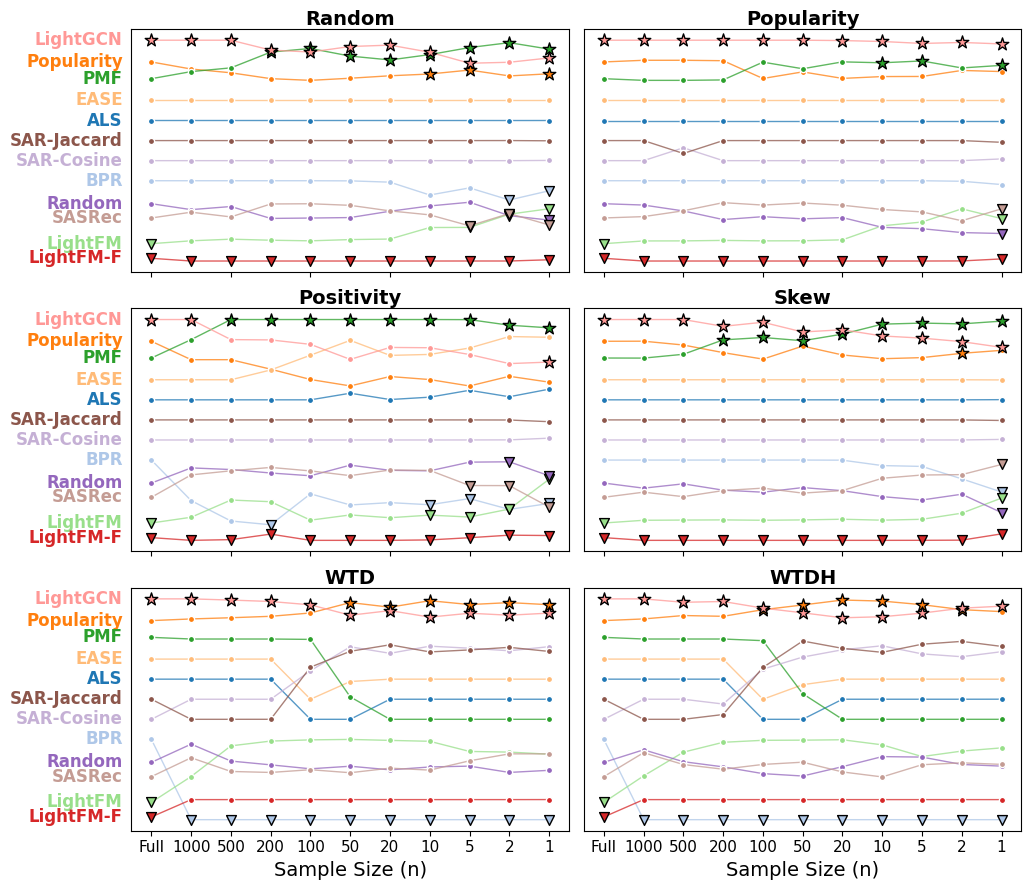

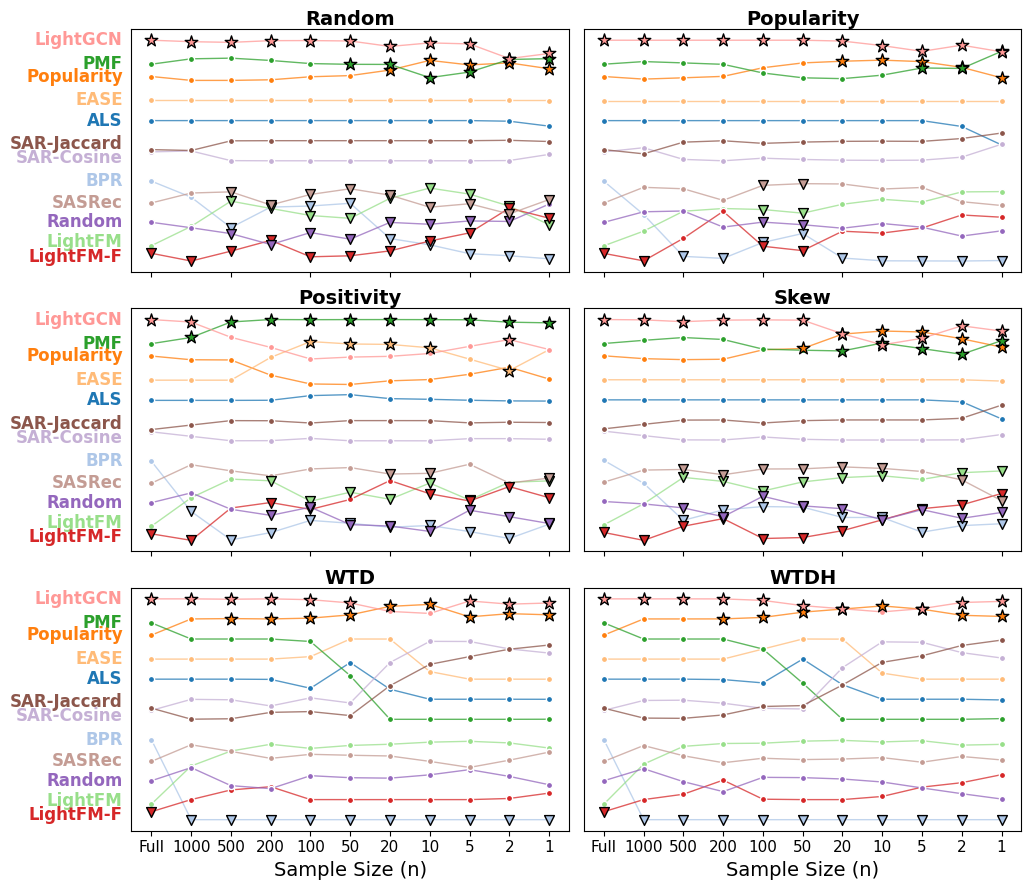

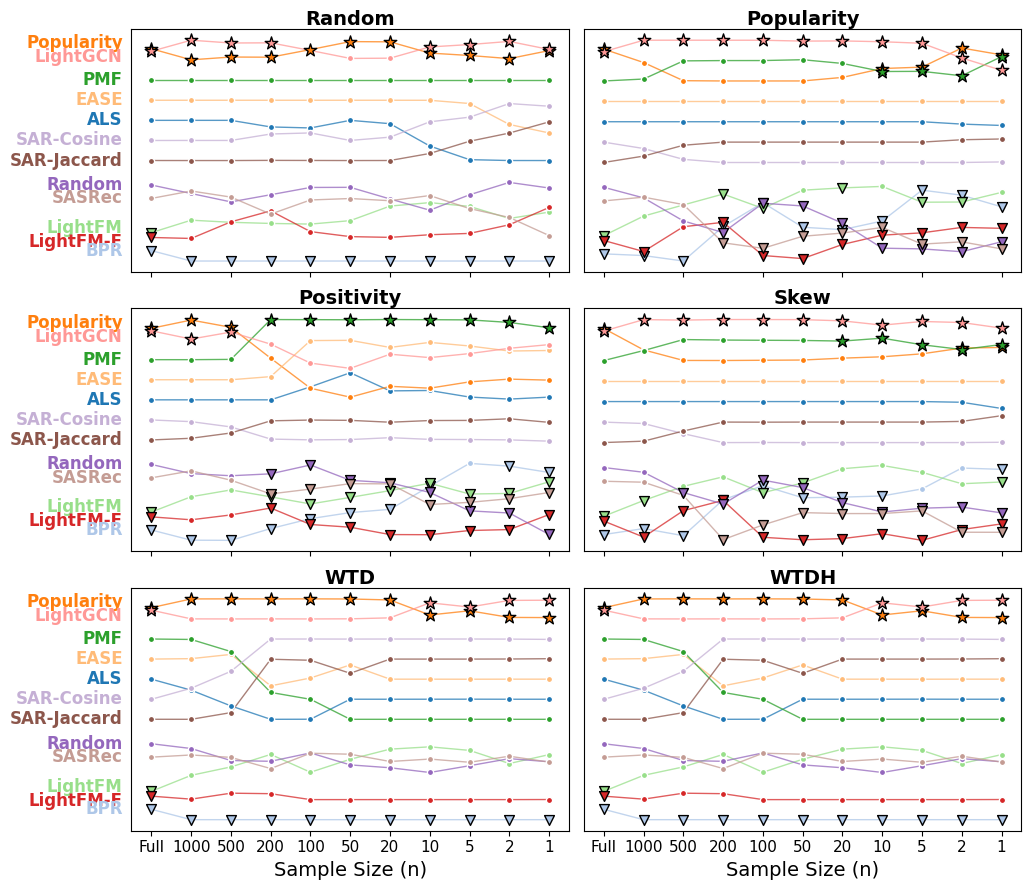

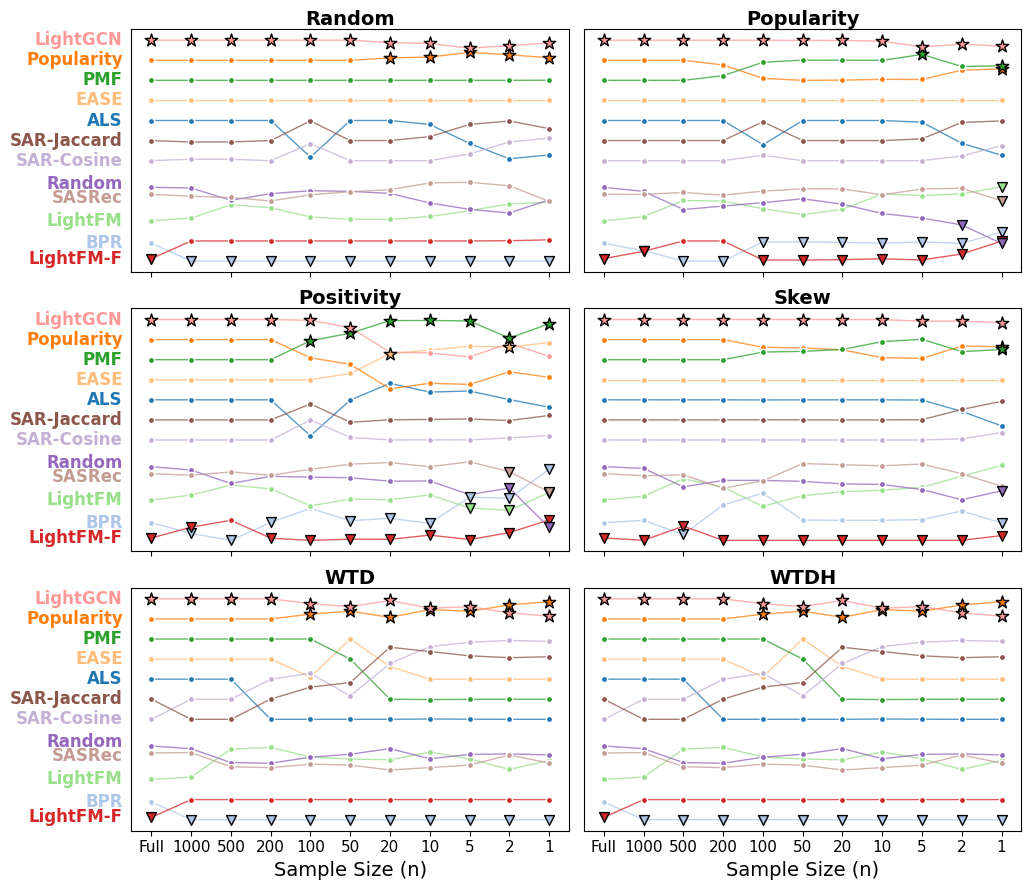

In [29]:
for bias in ["random0", "random95", "marpop95", "marpos95"]:
    single_samplers = SAMPLER_FAMILIES["Full"] # [v[0] for _, v in SAMPLER_FAMILIES.items() if len(v) == 1]
    dataset_list = []
    all_exp_df_pivot = (
        all_exp_df
        .query(f"bias == '{bias}'")
        .pivot(index=["userID", "model"], columns=["sampler"], values="metric")
        .reset_index()
    )
    for sampler_family, sampler_list in SAMPLER_FAMILIES.items():
        if len(sampler_list) == 1: continue
        dataset_list.append(
            (sampler_family.split("@")[0], all_exp_df_pivot.set_index("userID")[["model"] + single_samplers + sampler_list])
        )

    generate_stacked_ranking_figure_noalign(dataset_list, metric_families=SAMPLER_FAMILIES, output_file=f"q2_model_stability_{bias}.pdf")

In [ ]:
full_exp_df = (
    df_by_bias_type["random"]
    .query("result_key.str.contains('test_random0')")
    .query("result_key.str.contains('CNCFULL')")
)
metrics_df = full_exp_df["evaluation"].apply(pd.Series)
full_exp_df = pd.concat([full_exp_df, metrics_df], axis=1)

full_exp_df["model"] = full_exp_df["result_key"].str.split(":").str[-1].str.split("_").str[0]

user_hardness = full_exp_df.groupby("userID").agg({METRIC_NAME: "mean"})
user_hardness["difficulty_group"] = pd.qcut(
    1 - user_hardness[METRIC_NAME], q=4, labels=["Easy", "Medium", "Hard", "Very Hard"]
)

bymodel_evaluation = (
    full_exp_df.pivot(index="userID", columns="model", values=METRIC_NAME)
    .rename(columns=PAPER_MODEL_NAMES)
)

full_exp_df.head()

,imprID,userID,evaluation,size_candidates,sum_rating,result_key,group_auc,mean_mrr,mean_mrr@10,mean_mrr@100,...,unbiased_ndcg@50,unbiased_precision@10,unbiased_precision@100,unbiased_precision@5,unbiased_precision@50,unbiased_recall@10,unbiased_recall@100,unbiased_recall@5,unbiased_recall@50,model
0,14,14,"{'group_auc': 0.6582, 'mean_mrr': 0.0128, 'mea...",3327,179,train:clickpop_full-test_random0:clickpop_CNCFULL,0.6582,0.0128,0.4083,0.0922,...,0.0094,0.0010,0.0166,0.0000,0.0134,0.0062,0.0471,0.0015,0.0348,clickpop
1,19,19,"{'group_auc': 0.8274, 'mean_mrr': 0.0651, 'mea...",3327,40,train:clickpop_full-test_random0:clickpop_CNCFULL,0.8274,0.0651,0.3722,0.1283,...,0.0677,0.0278,0.1178,0.0147,0.1078,0.0537,0.2569,0.0315,0.2135,clickpop
2,21,21,"{'group_auc': 0.7833, 'mean_mrr': 0.0266, 'mea...",3327,112,train:clickpop_full-test_random0:clickpop_CNCFULL,0.7833,0.0266,0.4222,0.1032,...,0.0210,0.0100,0.0429,0.0062,0.0284,0.0157,0.1227,0.0092,0.0649,clickpop
3,23,23,"{'group_auc': 0.637, 'mean_mrr': 0.0069, 'mean...",3327,419,train:clickpop_full-test_random0:clickpop_CNCFULL,0.6370,0.0069,0.7500,0.0738,...,0.0045,0.0006,0.0095,0.0006,0.0046,0.0012,0.0351,0.0012,0.0169,clickpop
4,24,24,"{'group_auc': 0.621, 'mean_mrr': 0.0059, 'mean...",3327,329,train:clickpop_full-test_random0:clickpop_CNCFULL,0.6210,0.0059,0.3254,0.0655,...,0.0053,0.0017,0.0090,0.0009,0.0056,0.0053,0.0349,0.0016,0.0187,clickpop


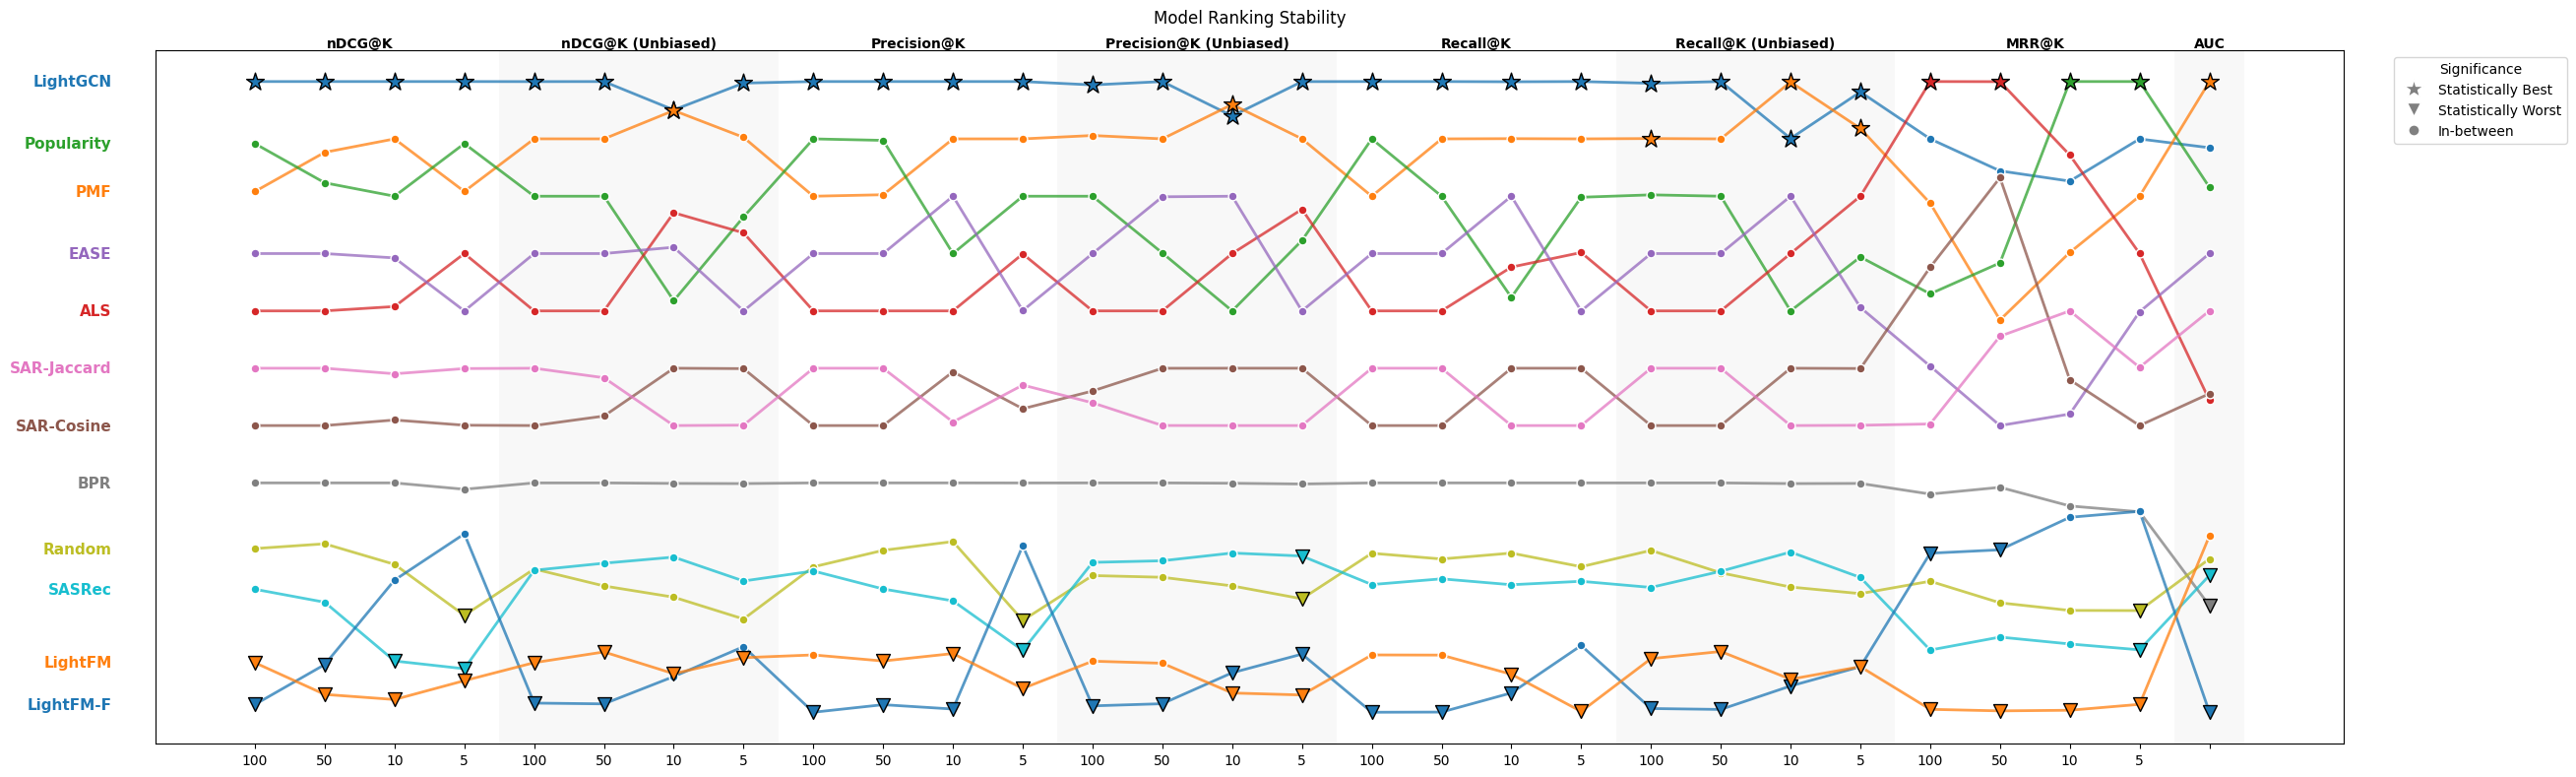

In [ ]:
generate_final_ranking_figure2(full_exp_df[["model"] + list(metrics_df.columns)])

Processing 1 datasets...
  -> Bootstrapping 'KuaiRec'...


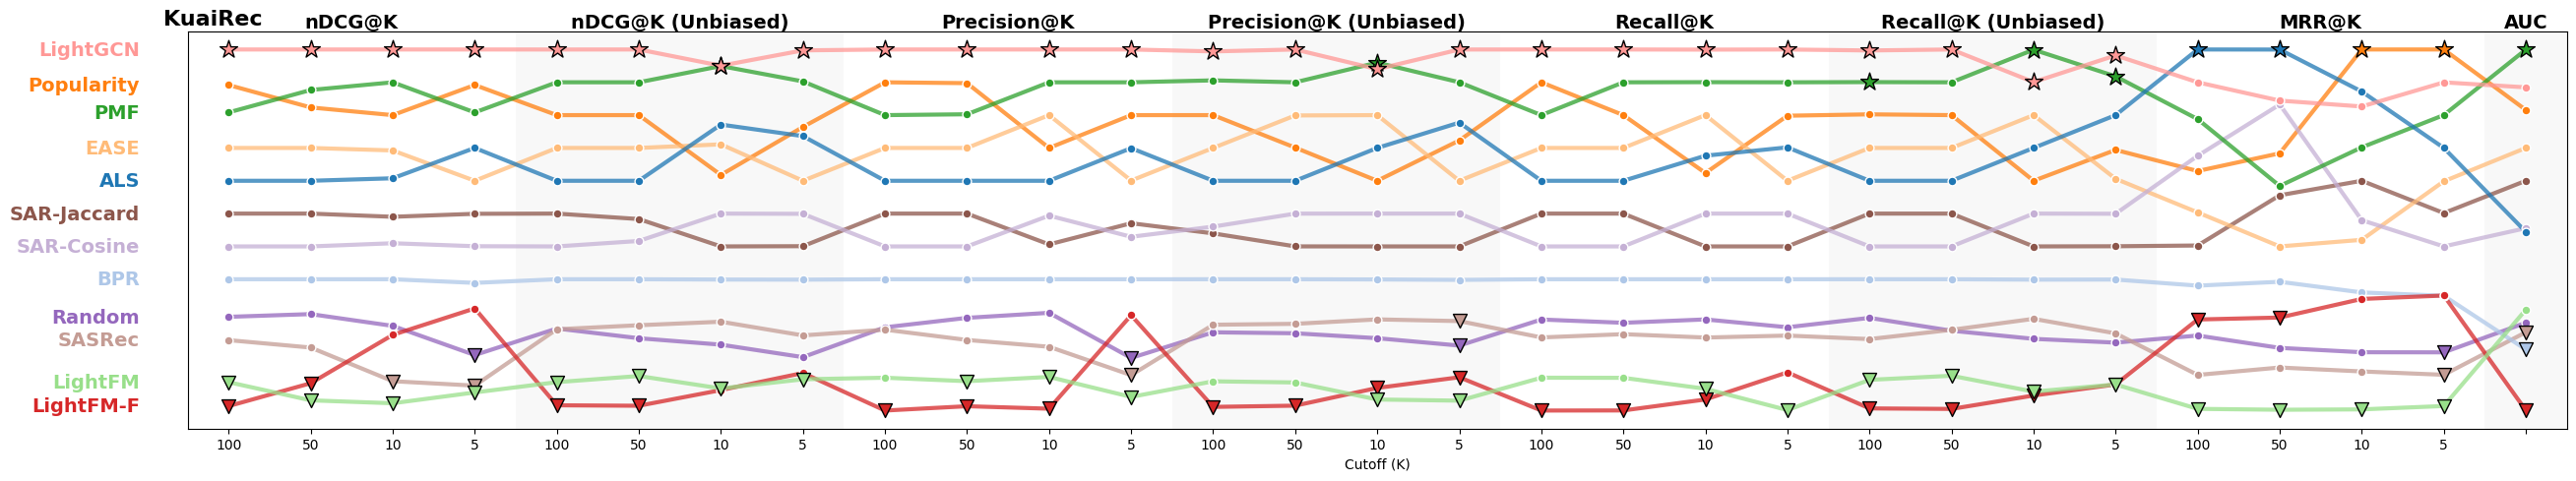

In [ ]:
generate_stacked_ranking_figure([["KuaiRec", full_exp_df[["model"] + list(metrics_df.columns)]]])

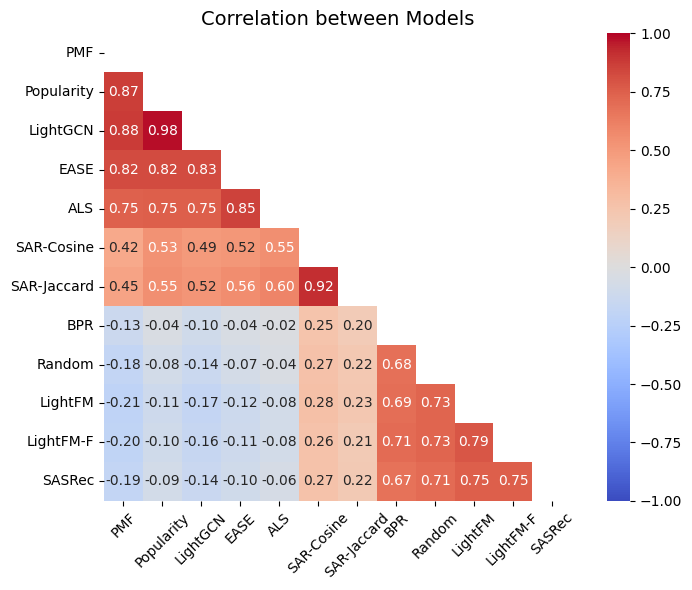

In [ ]:
plot_q_correlation_heatmap(bymodel_evaluation, title="Correlation between Models", method="pearson")

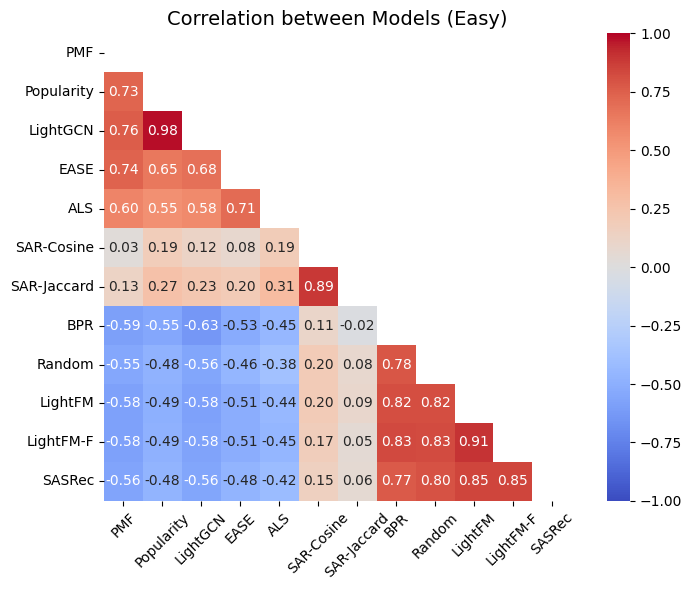

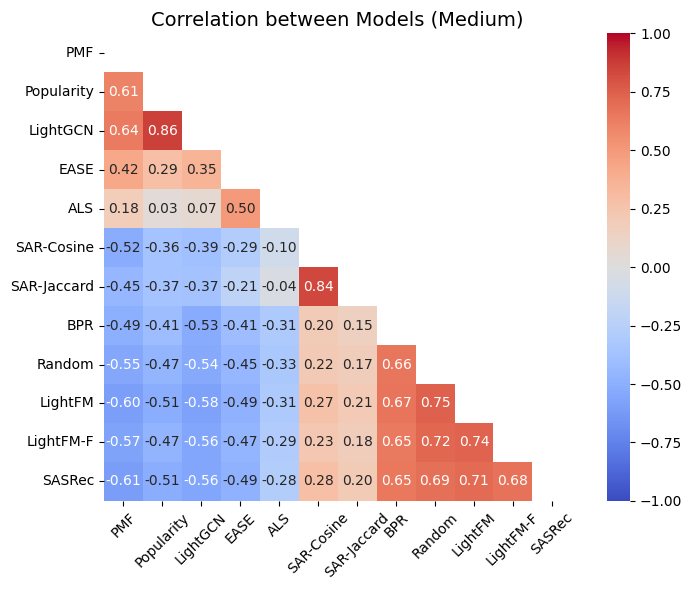

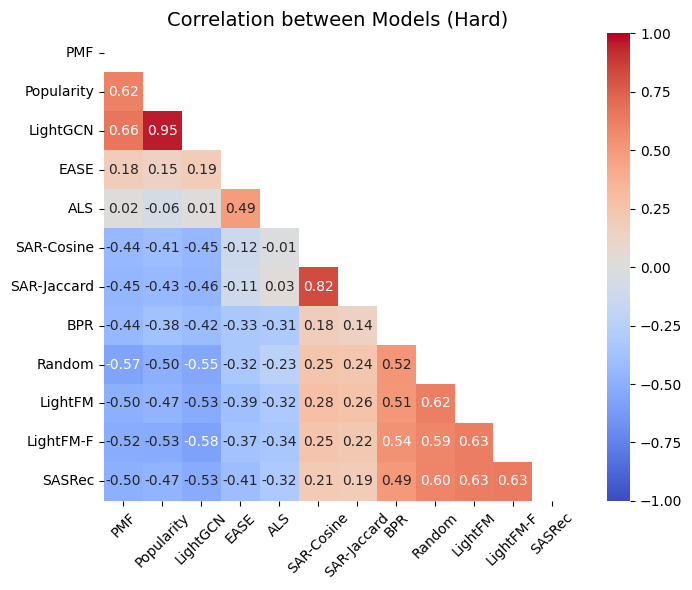

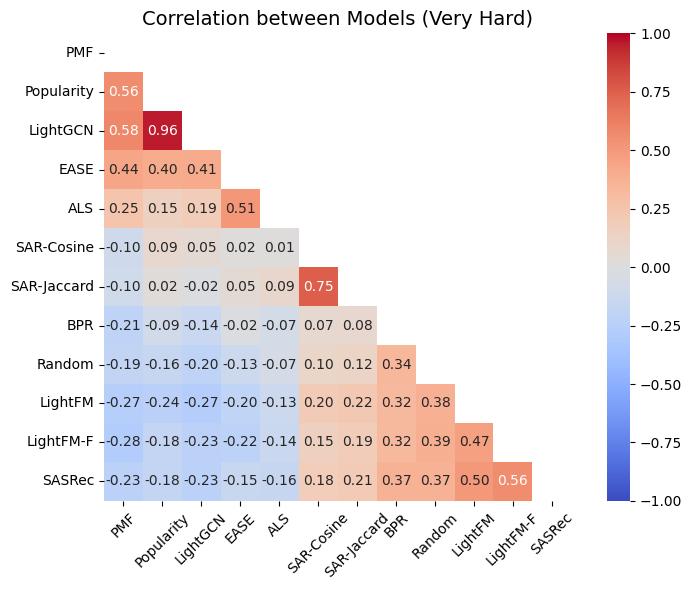

In [ ]:
plot_q_correlation_heatmap(bymodel_evaluation, user_hardness=user_hardness, title="Correlation between Models", method="pearson")

## R3

In [ ]:
CURRENT_RESULT_PATH = "/mnt/dados02/" + {os.environ['USER']} + "/sampling/data/r3/result/2026-02-26 00:00/2026-02-26 00:00_{}.parquet"

In [ ]:
bias_types = ["r3"]

for bias_type in bias_types:
    results_file = CURRENT_RESULT_PATH.format(bias_type)
    if os.path.exists(results_file):
        df = pd.read_parquet(results_file)
        if "rating" in df.columns:
            df["sum_rating"] = df["rating"].apply(sum)
        if "sum_rating" in df.columns:
            df = df.query("sum_rating > 0")
        if "pscore" in df.columns:
            df.drop(["pscore"], axis=1, inplace=True)
        df_by_bias_type[bias_type] = df
    else:
        print(f"File not found: {results_file}")

In [ ]:
r3_full_exp_df = (
    df_by_bias_type["r3"]
    .query("result_key.str.contains('CNCFULL')")
).copy()

r3_metrics_df = r3_full_exp_df["evaluation"].apply(pd.Series)
r3_full_exp_df = pd.concat([r3_full_exp_df, r3_metrics_df], axis=1)

r3_full_exp_df["model"] = r3_full_exp_df["result_key"].str.split(":").str[-1].str.split("_").str[0]

r3_user_hardness = r3_full_exp_df.groupby("userID").agg({METRIC_NAME: "mean"})
r3_user_hardness["difficulty_group"] = pd.qcut(
    1 - r3_user_hardness[METRIC_NAME], q=4, labels=["Easy", "Medium", "Hard", "Very Hard"]
)

r3_bymodel_evaluation = (
    r3_full_exp_df.pivot(index="userID", columns="model", values=METRIC_NAME)
    .rename(columns=PAPER_MODEL_NAMES)
)

r3_full_exp_df.head()

,imprID,userID,evaluation,size_candidates,sum_rating,result_key,group_auc,mean_mrr,mean_mrr@10,mean_mrr@100,...,unbiased_ndcg@50,unbiased_precision@10,unbiased_precision@100,unbiased_precision@5,unbiased_precision@50,unbiased_recall@10,unbiased_recall@100,unbiased_recall@5,unbiased_recall@50,model
0,1,1,"{'group_auc': 0.5018, 'mean_mrr': 0.0024, 'mea...",1000,2,train:clickpop_full-test_r3:clickpop_CNCFULL,0.5018,0.0024,0.0,0.0000,...,0.0000,0.0,0.0000,0.0,0.0000,0.0,0.0000,0.0,0.0000,clickpop
1,2,2,"{'group_auc': 0.5975, 'mean_mrr': 0.0037, 'mea...",1000,5,train:clickpop_full-test_r3:clickpop_CNCFULL,0.5975,0.0037,0.0,0.0000,...,0.0000,0.0,0.0000,0.0,0.0000,0.0,0.0000,0.0,0.0000,clickpop
2,3,3,"{'group_auc': 0.5748, 'mean_mrr': 0.0042, 'mea...",1000,8,train:clickpop_full-test_r3:clickpop_CNCFULL,0.5748,0.0042,0.0,0.0114,...,0.0000,0.0,0.0012,0.0,0.0000,0.0,0.1065,0.0,0.0000,clickpop
3,4,4,"{'group_auc': 0.5656, 'mean_mrr': 0.0057, 'mea...",1000,10,train:clickpop_full-test_r3:clickpop_CNCFULL,0.5656,0.0057,0.0,0.0165,...,0.0000,0.0,0.0052,0.0,0.0000,0.0,0.2040,0.0,0.0000,clickpop
4,5,5,"{'group_auc': 0.597, 'mean_mrr': 0.0083, 'mean...",1000,10,train:clickpop_full-test_r3:clickpop_CNCFULL,0.5970,0.0083,0.0,0.0314,...,0.0208,0.0,0.0074,0.0,0.0043,0.0,0.2028,0.0,0.0912,clickpop


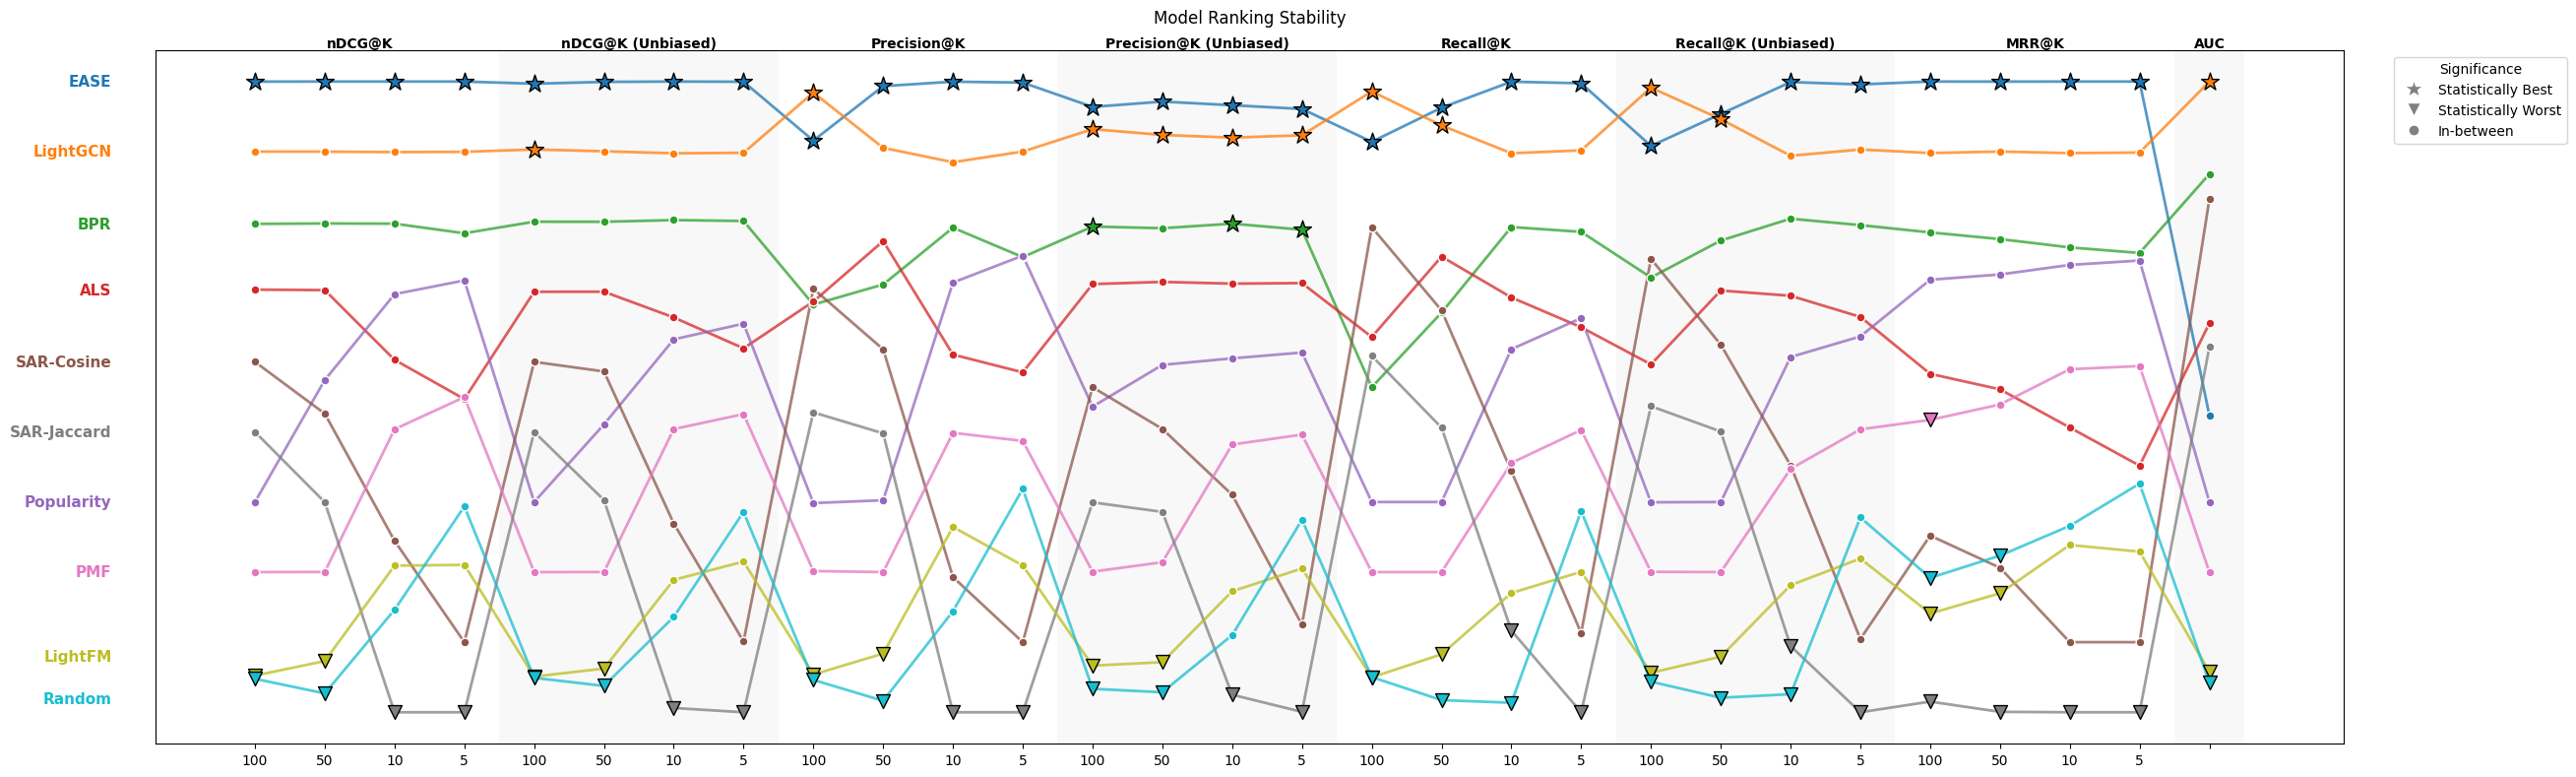

In [ ]:
generate_final_ranking_figure2(r3_full_exp_df[["model"] + list(r3_metrics_df.columns)])

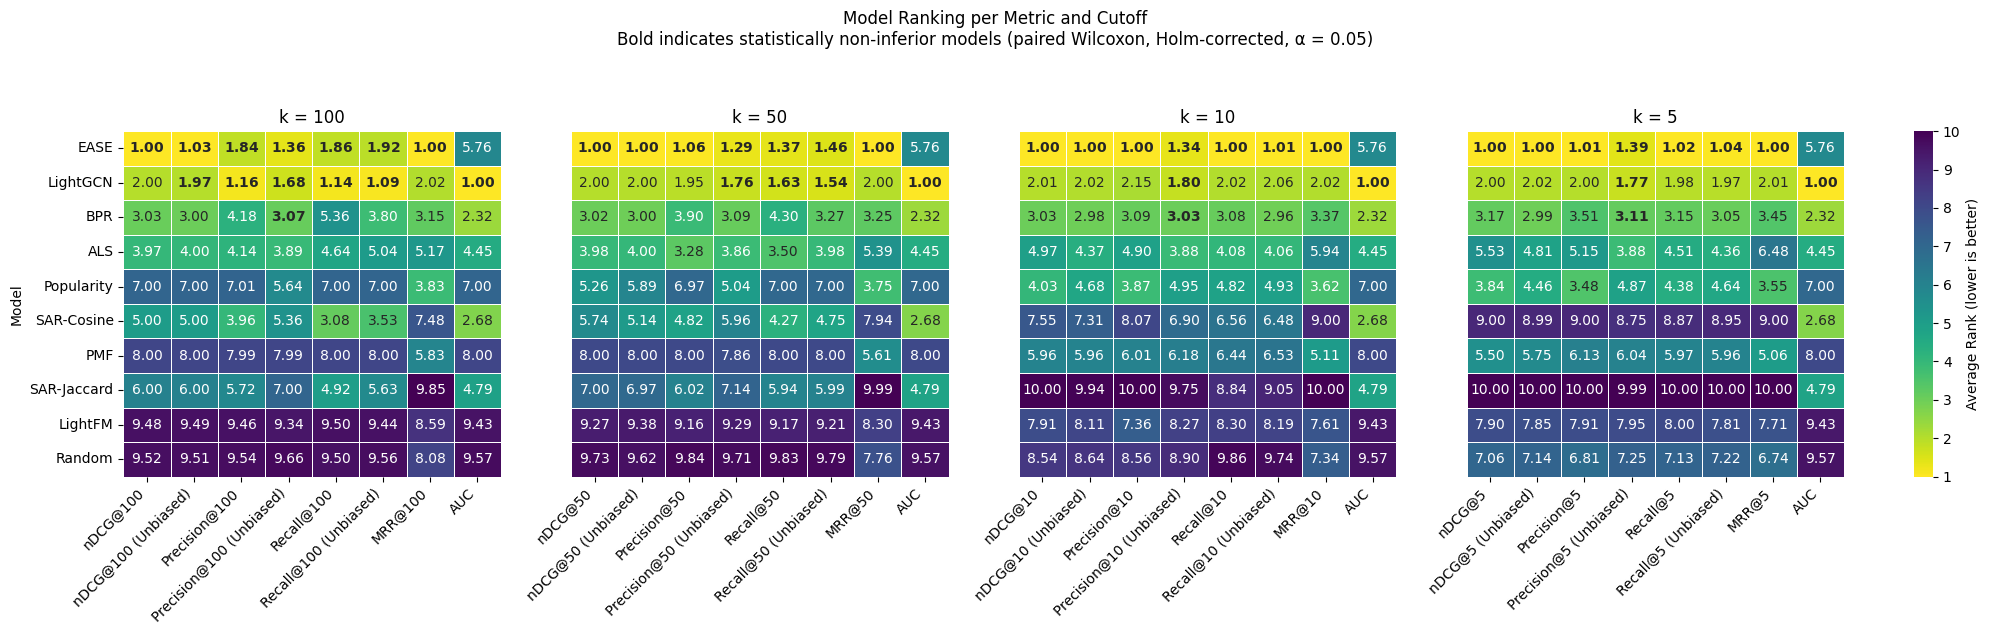

In [ ]:
generate_final_ranking_figure(r3_full_exp_df[["model"] + list(r3_metrics_df.columns)])

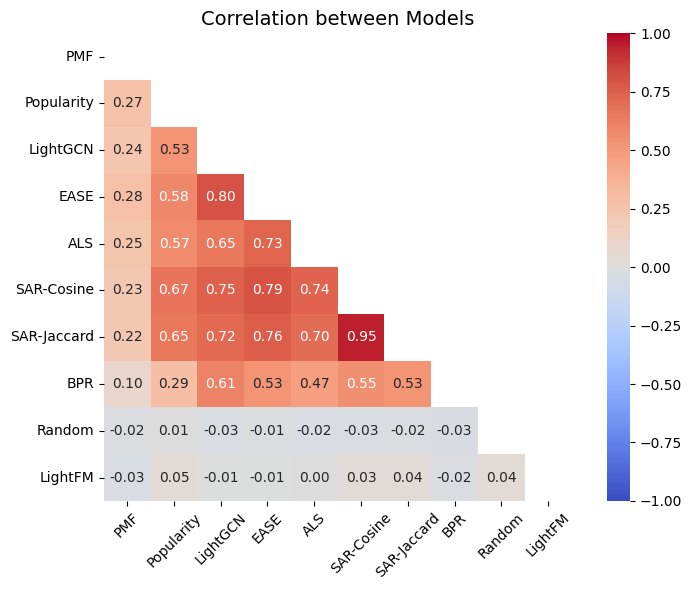

In [ ]:
plot_q_correlation_heatmap(r3_bymodel_evaluation, title="Correlation between Models", method="pearson")

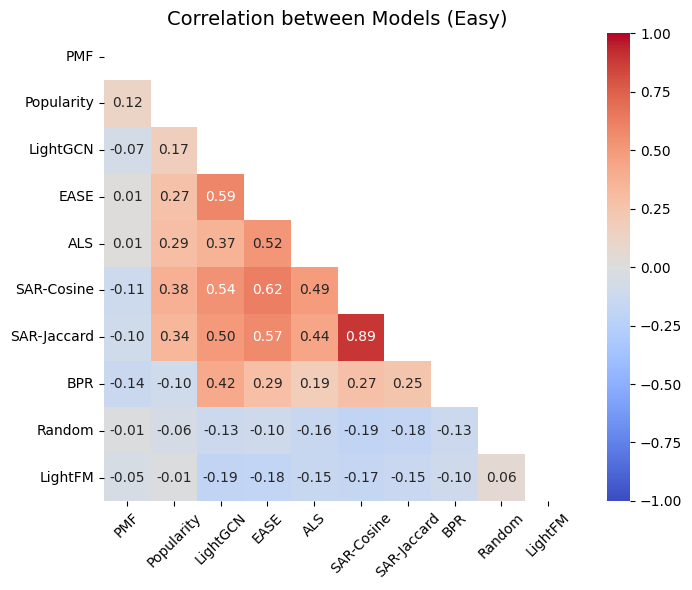

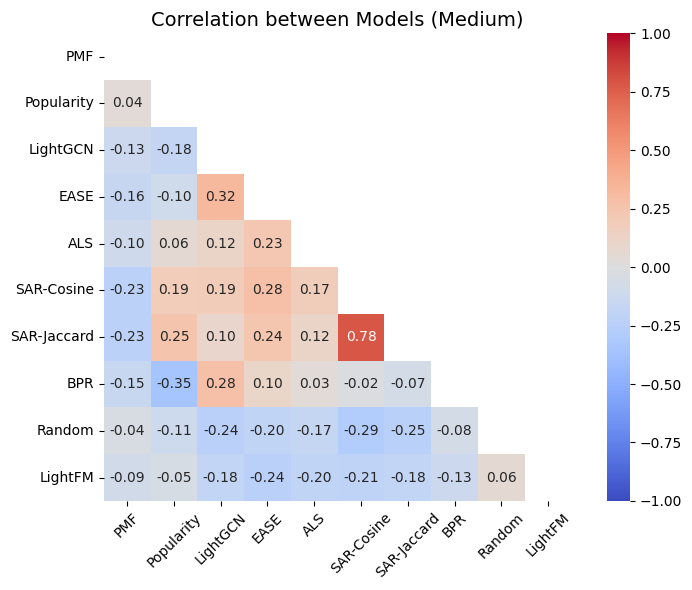

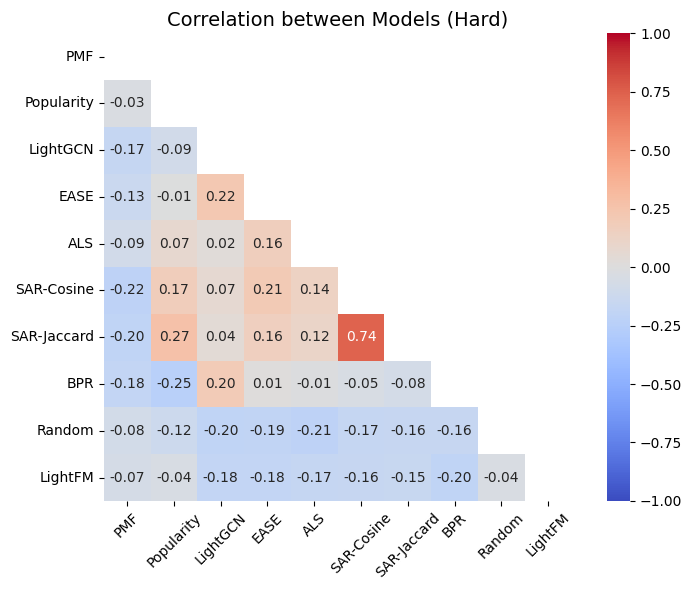

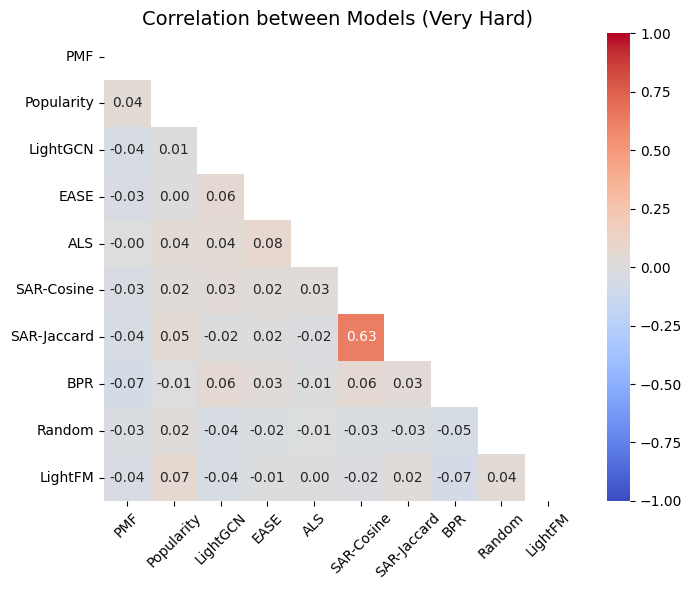

In [ ]:
plot_q_correlation_heatmap(r3_bymodel_evaluation, user_hardness=r3_user_hardness, title="Correlation between Models")

## Coat

In [ ]:
CURRENT_RESULT_PATH = "/mnt/dados02/" + {os.environ['USER']} + "/sampling/data/coat/result/2026-02-26 00:00/2026-02-26 00:00_{}.parquet"

In [ ]:
bias_types = ["coat"]

for bias_type in bias_types:
    results_file = CURRENT_RESULT_PATH.format(bias_type)
    if os.path.exists(results_file):
        df = pd.read_parquet(results_file)
        if "rating" in df.columns:
            df["sum_rating"] = df["rating"].apply(sum)
        if "sum_rating" in df.columns:
            df = df.query("sum_rating > 0")
        if "pscore" in df.columns:
            df.drop(["pscore"], axis=1, inplace=True)
        df_by_bias_type[bias_type] = df
    else:
        print(f"File not found: {results_file}")

In [ ]:
coat_full_exp_df = (
    df_by_bias_type["coat"]
    .query("result_key.str.contains('CNCFULL')")
).copy()

coat_metrics_df = coat_full_exp_df["evaluation"].apply(pd.Series)
coat_full_exp_df = pd.concat([coat_full_exp_df, coat_metrics_df], axis=1)
coat_full_exp_df["model"] = coat_full_exp_df["result_key"].str.split(":").str[-1].str.split("_").str[0]

coat_user_hardness = coat_full_exp_df.groupby("userID").agg({METRIC_NAME: "mean"})
coat_user_hardness["difficulty_group"] = pd.qcut(
    1 - coat_user_hardness[METRIC_NAME], q=4, labels=["Easy", "Medium", "Hard", "Very Hard"]
)

coat_bymodel_evaluation = (
    coat_full_exp_df.pivot(index="userID", columns="model", values=METRIC_NAME)
    .rename(columns=PAPER_MODEL_NAMES)
)

coat_full_exp_df.head()

,imprID,userID,propensity,evaluation,size_candidates,sum_rating,result_key,group_auc,mean_mrr,mean_mrr@10,...,unbiased_ndcg@50,unbiased_precision@10,unbiased_precision@100,unbiased_precision@5,unbiased_precision@50,unbiased_recall@10,unbiased_recall@100,unbiased_recall@5,unbiased_recall@50,model
0,0,0,"[[0.03463610261678696, 0.017863936722278595, 0...","{'group_auc': 0.4138, 'mean_mrr': 0.0121, 'mea...",300,6,train:lightgcn_full-test_coat:lightgcn_CNCFULL,0.4138,0.0121,0.0,...,0.0675,0.0,0.0137,0.0,0.0137,0.0,0.3008,0.0,0.3008,lightgcn
1,1,1,"[[0.02087393030524254, 0.01793249323964119, 0....","{'group_auc': 0.4582, 'mean_mrr': 0.0109, 'mea...",300,9,train:lightgcn_full-test_coat:lightgcn_CNCFULL,0.4582,0.0109,0.0,...,0.0073,0.0,0.0073,0.0,0.0014,0.0,0.2763,0.0,0.0335,lightgcn
2,2,2,"[[0.012933029793202877, 0.02177402935922146, 0...","{'group_auc': 0.7421, 'mean_mrr': 0.0152, 'mea...",300,7,train:lightgcn_full-test_coat:lightgcn_CNCFULL,0.7421,0.0152,0.0,...,0.1076,0.0,0.0511,0.0,0.0354,0.0,0.6590,0.0,0.5800,lightgcn
3,3,3,"[[0.025276850908994675, 0.024542920291423798, ...","{'group_auc': 0.51, 'mean_mrr': 0.0125, 'mean_...",300,7,train:lightgcn_full-test_coat:lightgcn_CNCFULL,0.5100,0.0125,0.0,...,0.0515,0.0,0.0237,0.0,0.0126,0.0,0.5775,0.0,0.2626,lightgcn
4,4,4,"[[0.020020579919219017, 0.020020579919219017, ...","{'group_auc': 0.499, 'mean_mrr': 0.0116, 'mean...",300,9,train:lightgcn_full-test_coat:lightgcn_CNCFULL,0.4990,0.0116,0.0,...,0.0298,0.0,0.0180,0.0,0.0075,0.0,0.4592,0.0,0.1541,lightgcn


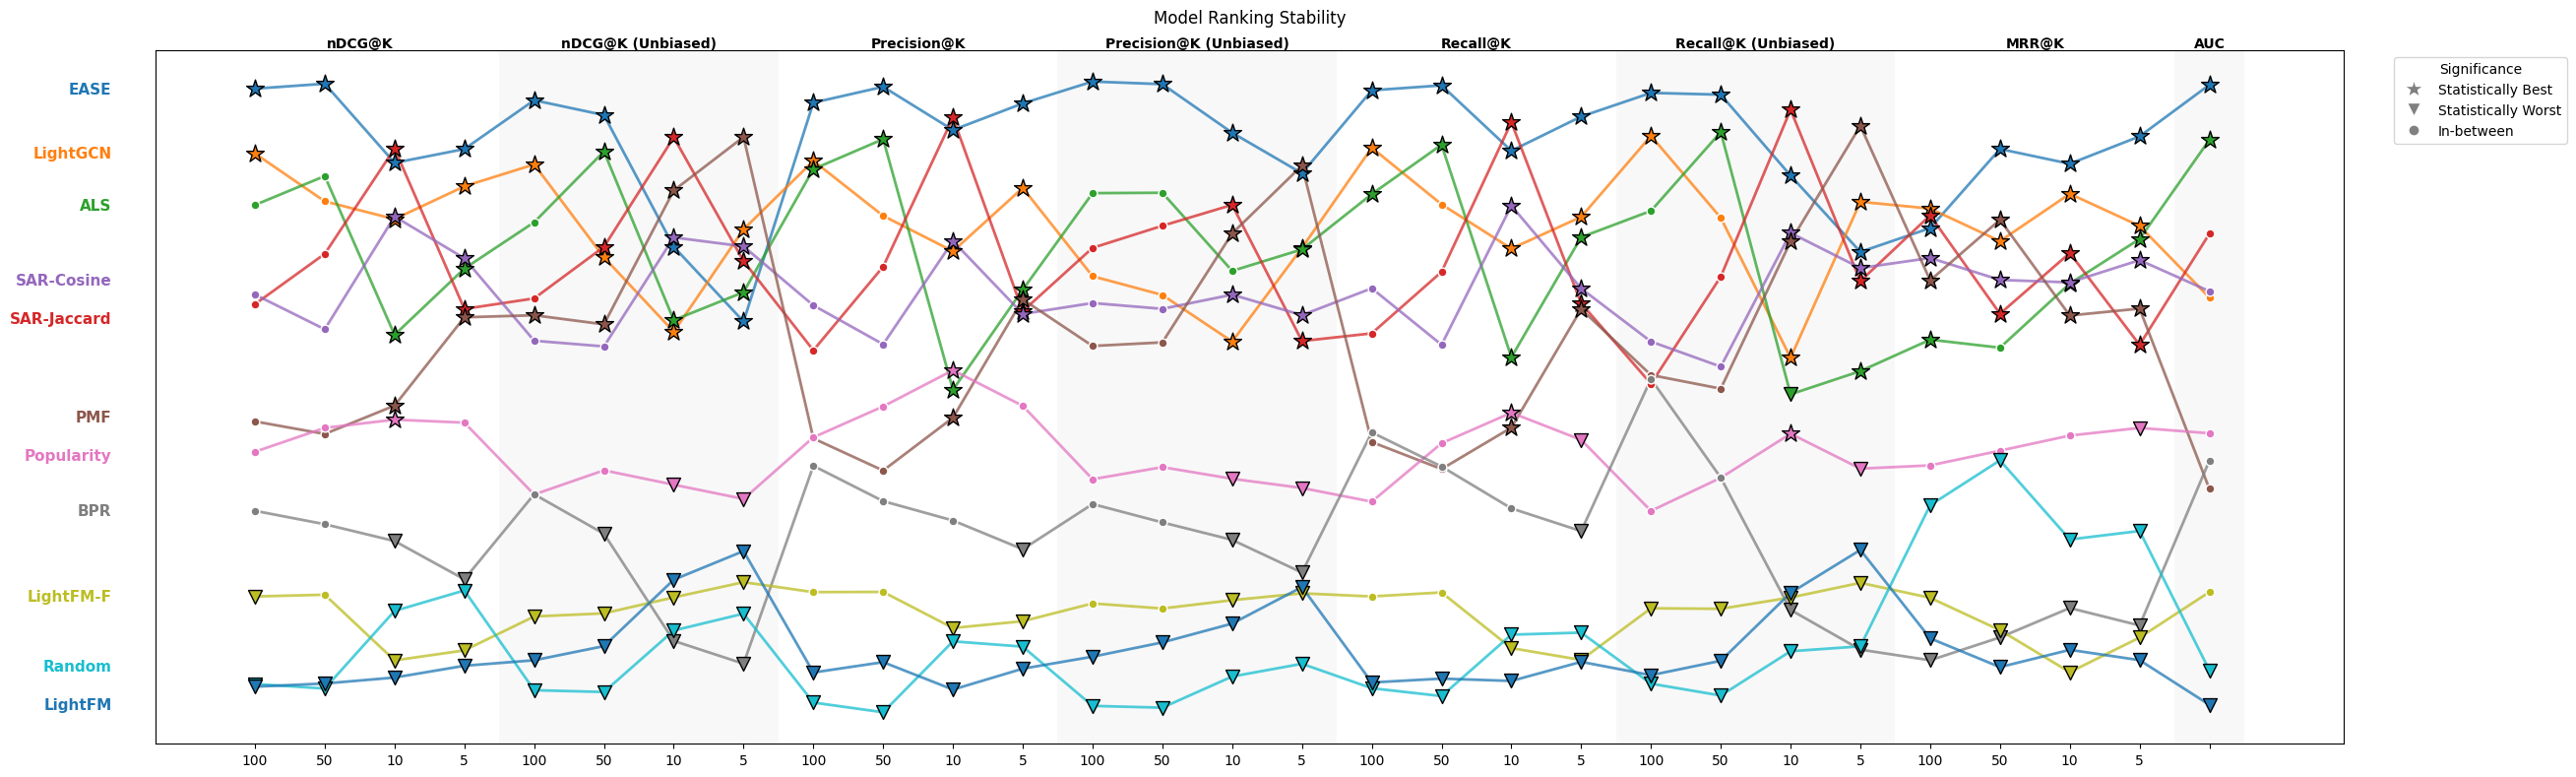

In [ ]:
generate_final_ranking_figure2(coat_full_exp_df[["model"] + list(coat_metrics_df.columns)])

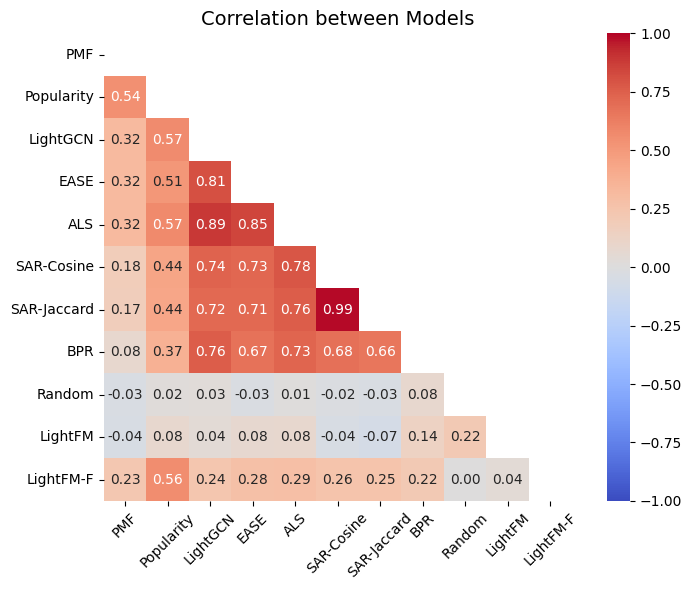

In [ ]:
plot_q_correlation_heatmap(coat_bymodel_evaluation, title="Correlation between Models", method="pearson")

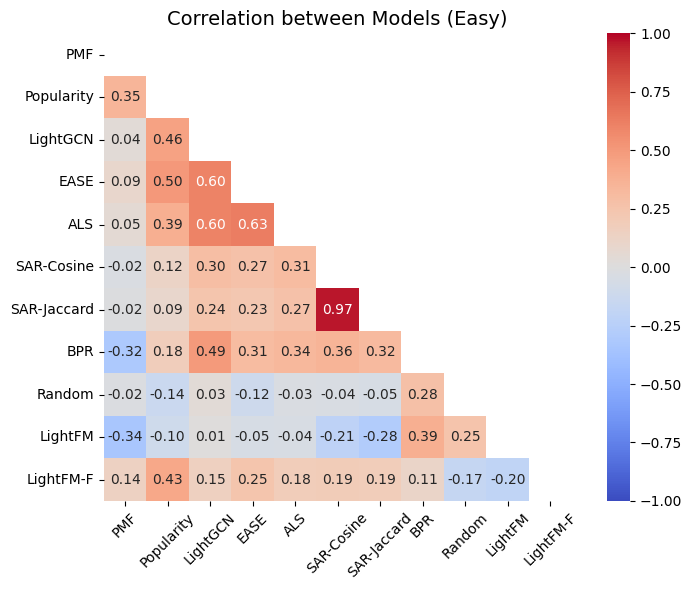

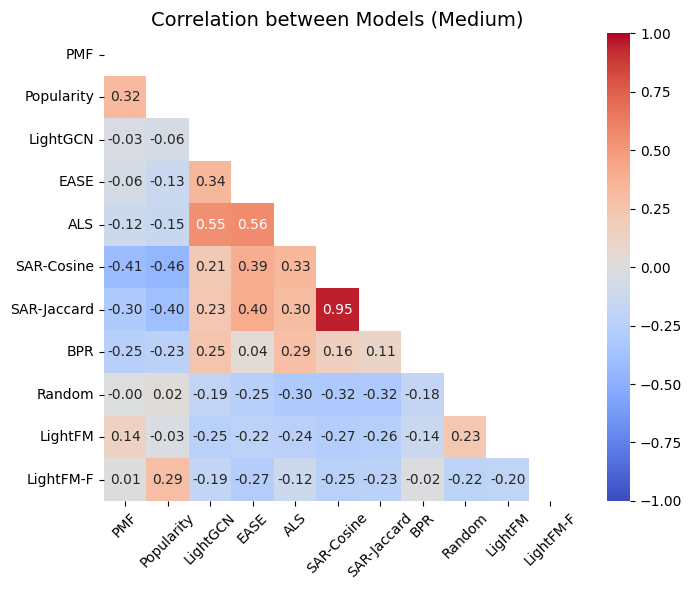

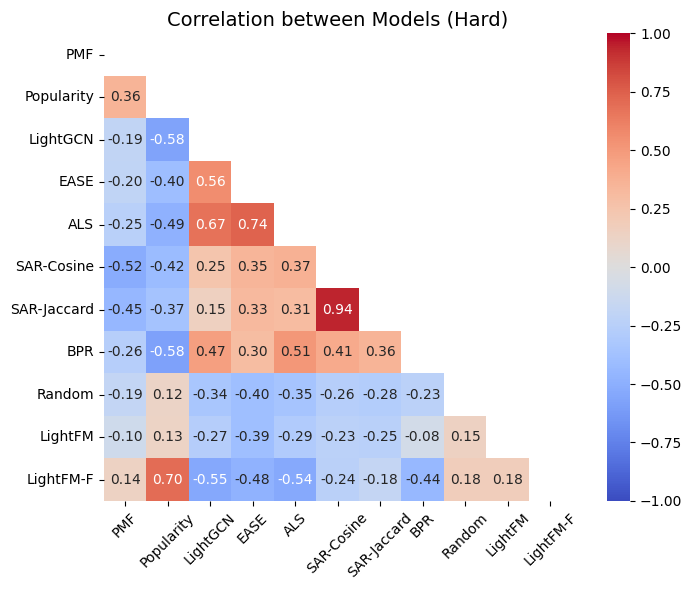

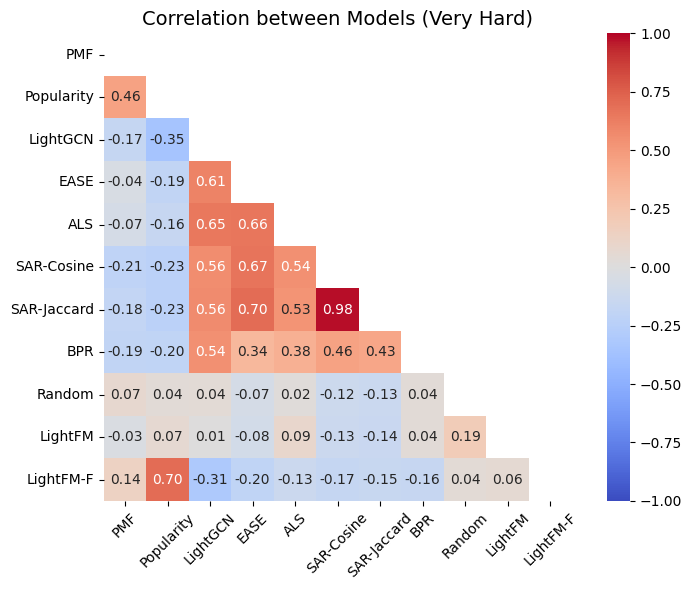

In [ ]:
plot_q_correlation_heatmap(coat_bymodel_evaluation, user_hardness=coat_user_hardness, title="Correlation between Models")

## All Datasets

Processing 3 datasets...
  -> Bootstrapping 'KuaiRec'...
  -> Bootstrapping 'Coat'...
  -> Bootstrapping 'R3'...


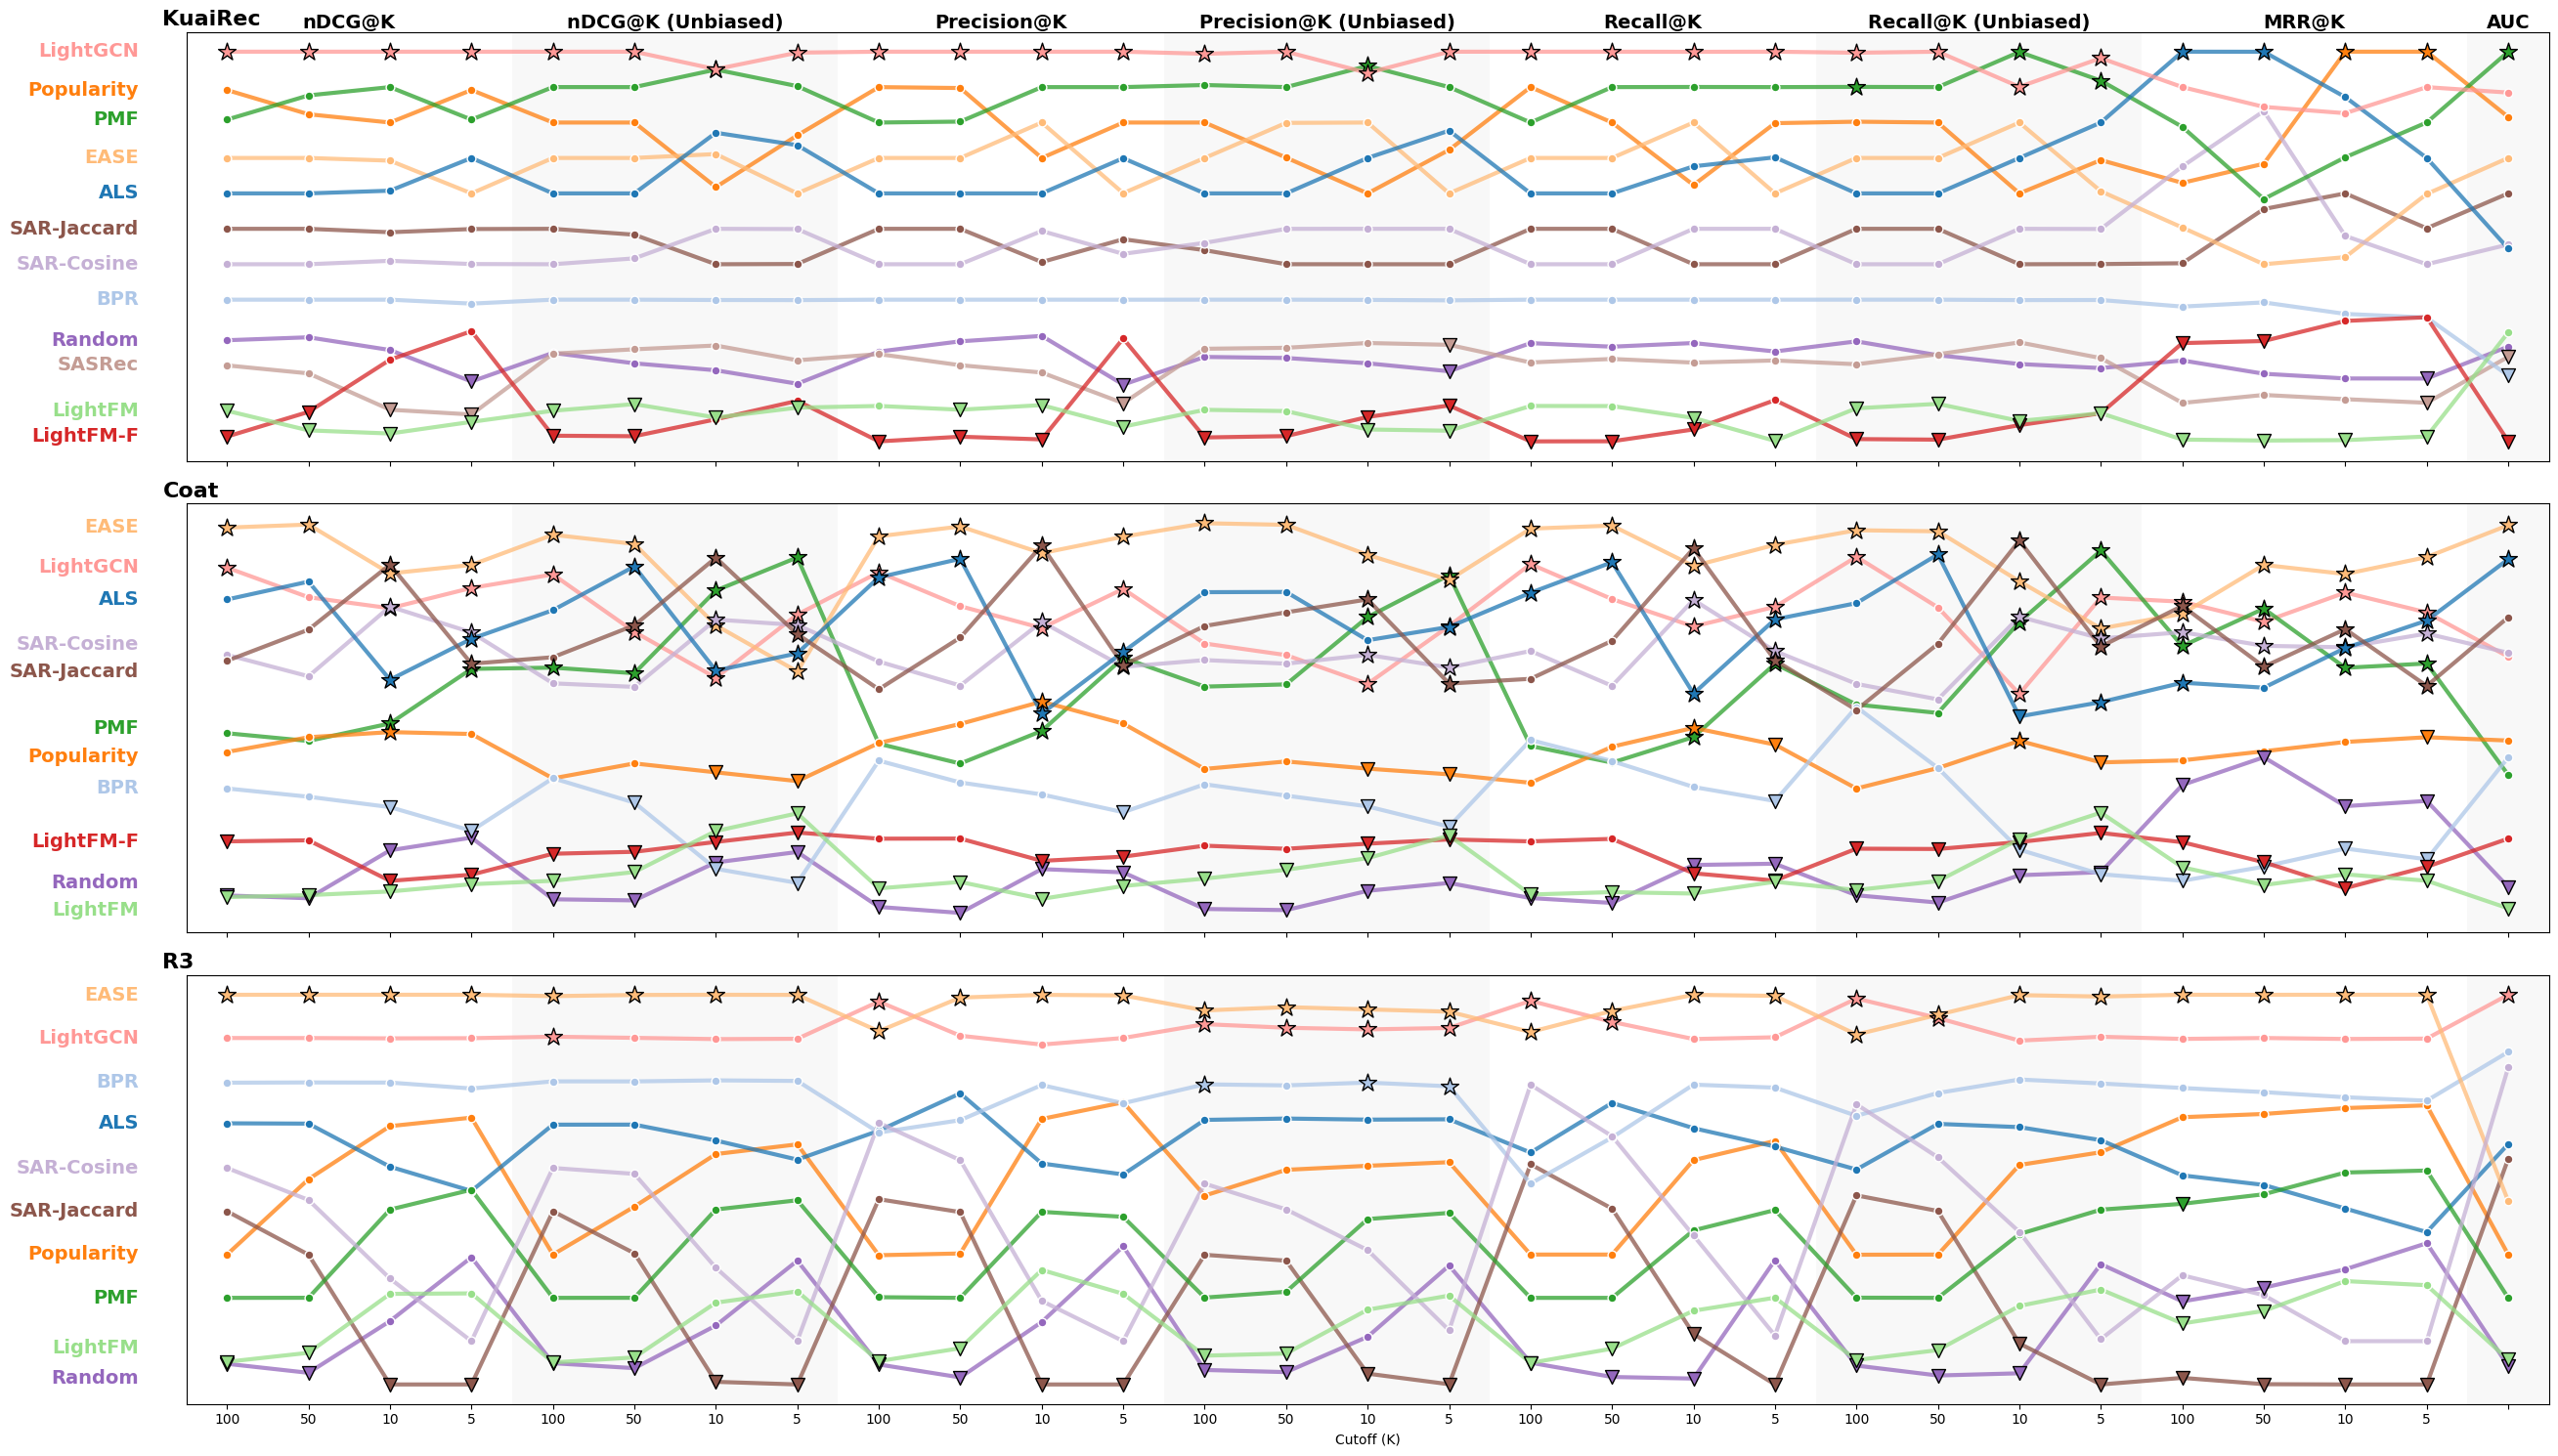

In [ ]:
generate_stacked_ranking_figure([
    ("KuaiRec", full_exp_df[["model"] + list(metrics_df.columns)]),
    ("Coat", coat_full_exp_df[["model"] + list(metrics_df.columns)]),
    ("R3",  r3_full_exp_df[["model"] + list(metrics_df.columns)])
])

/tmp/ipykernel_1478204/205003169.py:148: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=0.3, h_pad=0.3)


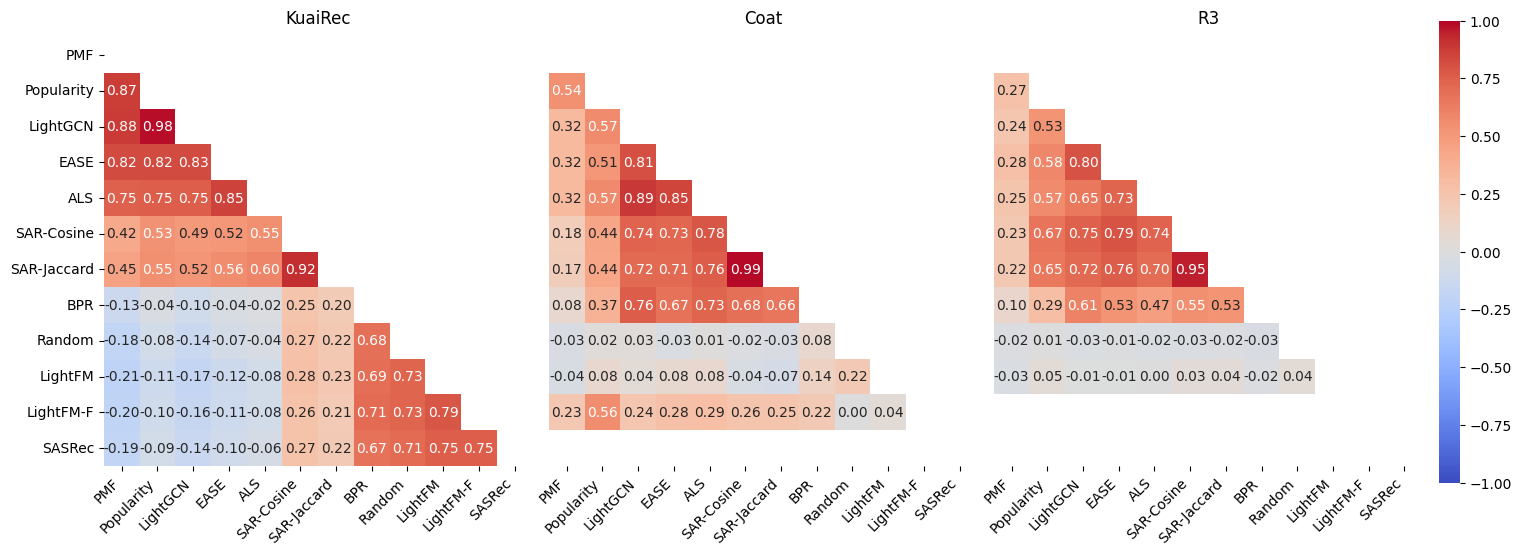

In [ ]:
plot_multiple_q_correlation_heatmaps(
    [("KuaiRec", bymodel_evaluation), ("Coat", coat_bymodel_evaluation), ("R3", r3_bymodel_evaluation)],
    title="Correlation between Models", method="pearson"
)